# 🔥 Fire & Smoke Semantic Segmentation — Dataset Pipeline

**Dataset**: `Fire_Smoke.v3i.png-mask-semantic` (Roboflow Export)

**Nội dung notebook**:
- **Phase 1**: Tách ảnh và mask vào 2 folder riêng
- **Phase 2**: Thống kê & Trực quan hóa EDA (publication-quality)
- **Phase 3**: Xử lý mất cân bằng lớp & Augmentation pipeline
- **Phase 4**: Tiền xử lý & PyTorch Dataset class cho training

---

## ⚙️ Cài đặt thư viện cần thiết

In [1]:
# Cài đặt các thư viện cần thiết (chạy 1 lần)
import subprocess, sys

packages = [
    'numpy', 'pandas', 'matplotlib', 'seaborn',
    'Pillow', 'opencv-python', 'tqdm',
    'albumentations', 'scikit-learn', 'torch', 'torchvision'
]

for pkg in packages:
    subprocess.run([sys.executable, '-m', 'pip', 'install', pkg, '-q'], check=False)

print('✅ Tất cả thư viện đã sẵn sàng!')

✅ Tất cả thư viện đã sẵn sàng!


In [2]:
# ===== IMPORTS TOÀN CỤC =====
import os
import shutil
import json
import warnings
import random
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
import seaborn as sns
from PIL import Image
import cv2
from tqdm.notebook import tqdm

warnings.filterwarnings('ignore')

# --- Style cho biểu đồ publication-quality ---
plt.rcParams.update({
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'font.family': 'DejaVu Sans',
    'font.size': 12,
    'axes.titlesize': 14,
    'axes.labelsize': 13,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 11,
    'figure.facecolor': 'white',
    'axes.facecolor': '#f8f9fa',
    'axes.grid': True,
    'grid.alpha': 0.3,
})
sns.set_palette('husl')

print('✅ Imports thành công!')

✅ Imports thành công!


In [3]:
# ===== CẤU HÌNH ĐƯỜNG DẪN =====
BASE_DIR   = Path(r'E:\NCKH\Code\Fire_Smoke_Early-Detection')
DATASET_DIR = BASE_DIR / 'Fire_Smoke.v3i.png-mask-semantic'
TRAIN_DIR  = DATASET_DIR / 'train'

# Output folders
IMAGES_DIR = DATASET_DIR / 'images'
MASKS_DIR  = DATASET_DIR / 'masks'
EDA_OUT    = BASE_DIR / 'docs' / 'eda_figures'

EDA_OUT.mkdir(parents=True, exist_ok=True)

print(f'📁 Dataset dir : {DATASET_DIR}')
print(f'📁 Train dir   : {TRAIN_DIR}')
print(f'📁 Output EDA  : {EDA_OUT}')
print(f'📊 Files in train/: {len(list(TRAIN_DIR.iterdir()))}')

📁 Dataset dir : E:\NCKH\Code\Fire_Smoke_Early-Detection\Fire_Smoke.v3i.png-mask-semantic
📁 Train dir   : E:\NCKH\Code\Fire_Smoke_Early-Detection\Fire_Smoke.v3i.png-mask-semantic\train
📁 Output EDA  : E:\NCKH\Code\Fire_Smoke_Early-Detection\docs\eda_figures
📊 Files in train/: 1871


---
# 📂 PHASE 1 — Tách thư mục `images/` và `masks/`

Tách toàn bộ files trong `train/` thành:
- `images/` ← chỉ chứa ảnh `.jpg`
- `masks/`  ← chỉ chứa mask `*_mask.png`

> **Lưu ý**: Copy (không move) để giữ nguyên thư mục `train/` gốc.

In [4]:
# ===== PHASE 1: Tách ảnh và mask =====

IMAGES_DIR.mkdir(parents=True, exist_ok=True)
MASKS_DIR.mkdir(parents=True, exist_ok=True)

img_count  = 0
mask_count = 0
skipped    = 0

all_files = sorted(TRAIN_DIR.iterdir())

for fpath in tqdm(all_files, desc='📋 Tách files'):
    fname = fpath.name

    if fname.endswith('_mask.png'):
        # Đây là mask
        dst = MASKS_DIR / fname
        if not dst.exists():
            shutil.copy2(fpath, dst)
        mask_count += 1

    elif fname.lower().endswith(('.jpg', '.jpeg', '.png')) and '_mask' not in fname:
        # Đây là ảnh gốc
        dst = IMAGES_DIR / fname
        if not dst.exists():
            shutil.copy2(fpath, dst)
        img_count += 1

    else:
        skipped += 1

print(f'\n✅ Phase 1 Hoàn thành!')
print(f'   🖼️  Ảnh (images/) : {img_count}')
print(f'   🎭 Mask (masks/)  : {mask_count}')
print(f'   ⚠️  Bỏ qua       : {skipped}')

📋 Tách files:   0%|          | 0/1871 [00:00<?, ?it/s]


✅ Phase 1 Hoàn thành!
   🖼️  Ảnh (images/) : 935
   🎭 Mask (masks/)  : 935
   ⚠️  Bỏ qua       : 1


In [5]:
# Kiểm tra ghép cặp ảnh - mask
images = {f.stem: f for f in IMAGES_DIR.glob('*.jpg')}
masks  = {f.stem.replace('_mask', ''): f for f in MASKS_DIR.glob('*_mask.png')}

paired   = set(images.keys()) & set(masks.keys())
img_only = set(images.keys()) - set(masks.keys())
msk_only = set(masks.keys())  - set(images.keys())

print(f'✅ Cặp ảnh-mask hợp lệ  : {len(paired)}')
print(f'⚠️  Ảnh KHÔNG có mask    : {len(img_only)}')
print(f'⚠️  Mask KHÔNG có ảnh    : {len(msk_only)}')

if img_only:
    print('\nẢnh thiếu mask (10 đầu):', list(img_only)[:10])
if msk_only:
    print('\nMask thiếu ảnh (10 đầu):', list(msk_only)[:10])

✅ Cặp ảnh-mask hợp lệ  : 935
⚠️  Ảnh KHÔNG có mask    : 0
⚠️  Mask KHÔNG có ảnh    : 0


---
# 📊 PHASE 2 — EDA: Thống kê & Trực quan hóa Dataset

## 2.1 — Đọc metadata và detect class từ mask

In [6]:
# ===== BƯỚC 2.1: Detect các màu/lớp trong mask =====
# Roboflow PNG Mask Semantic dùng màu RGB để encode class
# Cần detect tất cả unique colors để hiểu mapping

print('🔍 Scanning masks để detect unique pixel values...')

unique_values = set()
unique_colors = Counter()

mask_files = sorted(MASKS_DIR.glob('*_mask.png'))

# Sample 100 ảnh để detect nhanh
sample = random.sample(mask_files, min(100, len(mask_files)))

for mpath in tqdm(sample, desc='Scanning mask colors'):
    mask = np.array(Image.open(mpath))

    if mask.ndim == 3:  # RGB mask
        # Reshape to list of RGB tuples
        pixels = mask.reshape(-1, mask.shape[-1])
        for px in np.unique(pixels, axis=0):
            unique_colors[tuple(px)] += 1
    else:  # Grayscale mask (class index trực tiếp)
        for v in np.unique(mask):
            unique_values.add(int(v))

print('\n📋 Kết quả:')
if unique_colors:
    print('→ Mask dạng RGB. Unique colors tìm thấy:')
    for color, count in sorted(unique_colors.items(), key=lambda x: -x[1]):
        hex_c = '#{:02x}{:02x}{:02x}'.format(*color)
        print(f'   RGB{color} ({hex_c}) → xuất hiện trong {count}/{len(sample)} ảnh')
else:
    print('→ Mask dạng Grayscale (class index).')
    print('→ Unique values:', sorted(unique_values))

🔍 Scanning masks để detect unique pixel values...


Scanning mask colors:   0%|          | 0/100 [00:00<?, ?it/s]


📋 Kết quả:
→ Mask dạng Grayscale (class index).
→ Unique values: [0, 1, 2]


In [7]:
# ===== BƯỚC 2.2: Định nghĩa CLASS MAP dựa trên kết quả detect =====
# Điều chỉnh mapping này sau khi chạy cell trên!

# --- Roboflow Fire_Smoke thường dùng:
#   (0,0,0)       = background
#   (64,0,0)      = fire  (class 1)
#   (0,64,0)      = smoke (class 2)
# Nếu grayscale: 0=bg, 1=fire, 2=smoke

# Tự động detect và xây dựng CLASS_MAP
def build_class_map_from_colors(unique_colors_dict):
    """Tự động gán nhãn lớp dựa trên màu sắc phát hiện được."""
    colors = sorted(unique_colors_dict.keys())
    cmap = {}
    for i, c in enumerate(colors):
        if c == (0, 0, 0):
            cmap[c] = {'id': 0, 'name': 'background', 'color_vis': '#2c2c2c'}
        elif i == 1 or (c[0] > c[1] and c[0] > c[2]):  # đỏ nổi trội → fire
            cmap[c] = {'id': 1, 'name': 'fire', 'color_vis': '#FF4500'}
        elif i == 2:
            cmap[c] = {'id': 2, 'name': 'smoke', 'color_vis': '#708090'}
        else:
            cmap[c] = {'id': i, 'name': f'class_{i}', 'color_vis': f'#{i*40:02x}{i*60:02x}{i*80:02x}'}
    return cmap


# --- Nếu grayscale ---
def build_class_map_grayscale(unique_values_set):
    vals = sorted(unique_values_set)
    names = ['background', 'fire', 'smoke'] + [f'class_{i}' for i in range(3, len(vals))]
    colors = ['#2c2c2c', '#FF4500', '#708090'] + ['#8888ff'] * max(0, len(vals)-3)
    return {v: {'id': v, 'name': names[i], 'color_vis': colors[i]}
            for i, v in enumerate(vals)}


if unique_colors:
    CLASS_MAP = build_class_map_from_colors(unique_colors)
    MASK_MODE = 'RGB'
else:
    CLASS_MAP = build_class_map_grayscale(unique_values)
    MASK_MODE = 'GRAY'

print(f'MASK_MODE: {MASK_MODE}')
print('CLASS_MAP:')
for k, v in CLASS_MAP.items():
    print(f'  {k} → {v}')

MASK_MODE: GRAY
CLASS_MAP:
  0 → {'id': 0, 'name': 'background', 'color_vis': '#2c2c2c'}
  1 → {'id': 1, 'name': 'fire', 'color_vis': '#FF4500'}
  2 → {'id': 2, 'name': 'smoke', 'color_vis': '#708090'}


In [8]:
# ===== BƯỚC 2.3: Hàm tiện ích đọc mask → class index map =====

def mask_to_classmap(mask_path, mask_mode, class_map):
    """Đọc mask PNG → array 2D với giá trị = class id."""
    mask = np.array(Image.open(mask_path))

    if mask_mode == 'GRAY':
        if mask.ndim == 3:
            mask = mask[:, :, 0]
        return mask

    # RGB mode
    if mask.ndim == 2:
        return mask  # already grayscale somehow

    if mask.shape[2] == 4:
        mask = mask[:, :, :3]  # drop alpha

    class_arr = np.zeros(mask.shape[:2], dtype=np.uint8)
    for color, info in class_map.items():
        if len(color) == 3:
            match = np.all(mask == np.array(color, dtype=np.uint8), axis=-1)
            class_arr[match] = info['id']
    return class_arr


def get_class_pixel_counts(class_arr, n_classes):
    """Trả về dict {class_id: pixel_count}."""
    total = class_arr.size
    counts = {}
    for cid in range(n_classes):
        counts[cid] = int(np.sum(class_arr == cid))
    return counts, total


N_CLASSES = len(CLASS_MAP)
CLASS_NAMES = [info['name'] for info in CLASS_MAP.values()]
CLASS_COLORS = [info['color_vis'] for info in CLASS_MAP.values()]

print(f'Số lớp: {N_CLASSES}')
print(f'Tên lớp: {CLASS_NAMES}')

Số lớp: 3
Tên lớp: ['background', 'fire', 'smoke']


## 2.4 — Thống kê chi tiết từng ảnh (tạo DataFrame)

In [10]:
# ===== BƯỚC 2.4: Thu thập metadata từng ảnh =====
# Chạy cell này ~2-5 phút tùy số lượng ảnh

records = []

paired_list = sorted(paired)  # danh sách các base names hợp lệ

for base in tqdm(paired_list, desc='📊 Đang phân tích dataset'):
    img_path  = images[base]
    mask_path = masks[base]

    # --- Đọc ảnh ---
    try:
        img = Image.open(img_path)
        W, H = img.size
        channels = len(img.getbands())
        img_size_kb = img_path.stat().st_size / 1024
    except Exception as e:
        print(f'Lỗi ảnh {base}: {e}')
        continue

    # --- Đọc mask ---
    try:
        class_arr = mask_to_classmap(mask_path, MASK_MODE, CLASS_MAP)
        mask_size_kb = mask_path.stat().st_size / 1024
        mH, mW = class_arr.shape
    except Exception as e:
        print(f'Lỗi mask {base}: {e}')
        continue

    # --- Pixel counts ---
    counts, total_px = get_class_pixel_counts(class_arr, N_CLASSES)

    # --- Ghi record ---
    rec = {
        'basename'     : base,
        'img_path'     : str(img_path),
        'mask_path'    : str(mask_path),
        'width'        : W,
        'height'       : H,
        'channels'     : channels,
        'aspect_ratio' : round(W / H, 4),
        'img_size_kb'  : round(img_size_kb, 2),
        'mask_size_kb' : round(mask_size_kb, 2),
        'total_pixels' : total_px,
        'size_match'   : (W == mW and H == mH),
    }

    # Thêm pixel counts từng lớp
    for cid, cname in enumerate(CLASS_NAMES):
        px = counts.get(cid, 0)
        rec[f'px_{cname}']  = px
        rec[f'pct_{cname}'] = round(100 * px / total_px, 4) if total_px > 0 else 0.0

    # Flag: ảnh có chứa lớp đó không (>0.1% diện tích)
    for cid, cname in enumerate(CLASS_NAMES):
        if cname != 'background':
            rec[f'has_{cname}'] = rec[f'pct_{cname}'] > 0.1

    # Số lớp foreground xuất hiện trong ảnh
    fg_names = [n for n in CLASS_NAMES if n != 'background']
    rec['n_fg_classes'] = sum(rec.get(f'has_{n}', False) for n in fg_names)

    records.append(rec)

df = pd.DataFrame(records)
print(f'\n✅ Đã phân tích {len(df)} ảnh!')
df.head(20)

📊 Đang phân tích dataset:   0%|          | 0/935 [00:00<?, ?it/s]


✅ Đã phân tích 935 ảnh!


,basename,img_path,mask_path,width,height,channels,aspect_ratio,img_size_kb,mask_size_kb,total_pixels,size_match,px_background,pct_background,px_fire,pct_fire,px_smoke,pct_smoke,has_fire,has_smoke,n_fg_classes
0,000000_ClosingYourBedroomDoorCouldSaveYourLife...,E:\NCKH\Code\Fire_Smoke_Early-Detection\Fire_S...,E:\NCKH\Code\Fire_Smoke_Early-Detection\Fire_S...,640,640,3,1.0000,21.35,2.16,409600,True,403404,98.4873,6196,1.5127,0,0.0000,True,False,1
1,000000_train_2302_jpg.rf.11216a56d26cb25aa4cc6...,E:\NCKH\Code\Fire_Smoke_Early-Detection\Fire_S...,E:\NCKH\Code\Fire_Smoke_Early-Detection\Fire_S...,1080,1920,3,0.5625,133.42,5.66,2073600,True,2065839,99.6257,7761,0.3743,0,0.0000,True,False,1
2,000002_test_795_jpg.rf.90bb6c38e0ffd3dd2c95358...,E:\NCKH\Code\Fire_Smoke_Early-Detection\Fire_S...,E:\NCKH\Code\Fire_Smoke_Early-Detection\Fire_S...,1280,720,3,1.7778,43.23,2.62,921600,True,920326,99.8618,1274,0.1382,0,0.0000,True,False,1
3,000004_train_1858_jpg.rf.b067c7fadfba4b8f37dce...,E:\NCKH\Code\Fire_Smoke_Early-Detection\Fire_S...,E:\NCKH\Code\Fire_Smoke_Early-Detection\Fire_S...,1280,720,3,1.7778,89.87,3.09,921600,True,914204,99.1975,7396,0.8025,0,0.0000,True,False,1
4,000005_20test740_jpg.rf.dd2e54d31f5884a0d54444...,E:\NCKH\Code\Fire_Smoke_Early-Detection\Fire_S...,E:\NCKH\Code\Fire_Smoke_Early-Detection\Fire_S...,416,416,3,1.0000,27.07,1.65,173056,True,161947,93.5807,0,0.0000,11109,6.4193,False,True,1
5,000006_8test9165_jpg.rf.d76b3c8cb14d9fe1369bad...,E:\NCKH\Code\Fire_Smoke_Early-Detection\Fire_S...,E:\NCKH\Code\Fire_Smoke_Early-Detection\Fire_S...,416,416,3,1.0000,26.69,1.83,173056,True,152870,88.3356,129,0.0745,20057,11.5899,False,True,1
6,000007_frame_0000938_png_jpg.rf.92cea3df62d810...,E:\NCKH\Code\Fire_Smoke_Early-Detection\Fire_S...,E:\NCKH\Code\Fire_Smoke_Early-Detection\Fire_S...,640,640,3,1.0000,26.48,4.00,409600,True,302836,73.9346,236,0.0576,106528,26.0078,False,True,1
7,000008_train_4174_jpg.rf.5a35902bb6065f4c9af63...,E:\NCKH\Code\Fire_Smoke_Early-Detection\Fire_S...,E:\NCKH\Code\Fire_Smoke_Early-Detection\Fire_S...,960,540,3,1.7778,15.80,2.32,518400,True,510121,98.4030,8279,1.5970,0,0.0000,True,False,1
8,000010_2031_jpg.rf.fbc0f3742c7b4d349bd3eeb0c56...,E:\NCKH\Code\Fire_Smoke_Early-Detection\Fire_S...,E:\NCKH\Code\Fire_Smoke_Early-Detection\Fire_S...,640,640,3,1.0000,28.06,4.02,409600,True,312516,76.2979,8187,1.9988,88897,21.7034,True,True,2
9,000012_test_452_jpg.rf.ece1689d601892084e7182e...,E:\NCKH\Code\Fire_Smoke_Early-Detection\Fire_S...,E:\NCKH\Code\Fire_Smoke_Early-Detection\Fire_S...,1280,720,3,1.7778,41.17,4.25,921600,True,849035,92.1262,72565,7.8738,0,0.0000,True,False,1


In [11]:
# Lưu CSV thống kê
csv_path = EDA_OUT / 'eda_report.csv'
df.to_csv(csv_path, index=False)
print(f'✅ Đã lưu: {csv_path}')

# Tổng quan nhanh
print('\n' + '='*60)
print('THỐNG KÊ TỔNG QUAN')
print('='*60)
print(f'  Tổng số ảnh hợp lệ     : {len(df)}')
print(f'  Kích thước ảnh (W×H)   :')
print(f'    Min  : {df.width.min()}×{df.height.min()}')
print(f'    Max  : {df.width.max()}×{df.height.max()}')
print(f'    Mean : {df.width.mean():.0f}×{df.height.mean():.0f}')
print(f'  Dung lượng ảnh (KB)    :')
print(f'    Min={df.img_size_kb.min():.1f}, Max={df.img_size_kb.max():.1f}, Mean={df.img_size_kb.mean():.1f}')

print()
for cname in CLASS_NAMES:
    if cname == 'background': continue
    n_has = df[f'has_{cname}'].sum() if f'has_{cname}' in df.columns else 'N/A'
    pct   = df[f'pct_{cname}'].mean() if f'pct_{cname}' in df.columns else 0
    print(f'  Ảnh có {cname:8s}         : {n_has}/{len(df)} ({100*n_has/len(df):.1f}%)')
    print(f'    Avg pixel coverage    : {pct:.2f}%')
print(f'  Ảnh size mismatch       : {(~df.size_match).sum()}')

✅ Đã lưu: E:\NCKH\Code\Fire_Smoke_Early-Detection\docs\eda_figures\eda_report.csv

THỐNG KÊ TỔNG QUAN
  Tổng số ảnh hợp lệ     : 935
  Kích thước ảnh (W×H)   :
    Min  : 224×176
    Max  : 3840×2160
    Mean : 1066×710
  Dung lượng ảnh (KB)    :
    Min=6.2, Max=877.9, Mean=91.5

  Ảnh có fire             : 570/935 (61.0%)
    Avg pixel coverage    : 1.19%
  Ảnh có smoke            : 451/935 (48.2%)
    Avg pixel coverage    : 5.29%
  Ảnh size mismatch       : 0


## 2.5 — Trực quan hóa (Publication-Quality Figures)

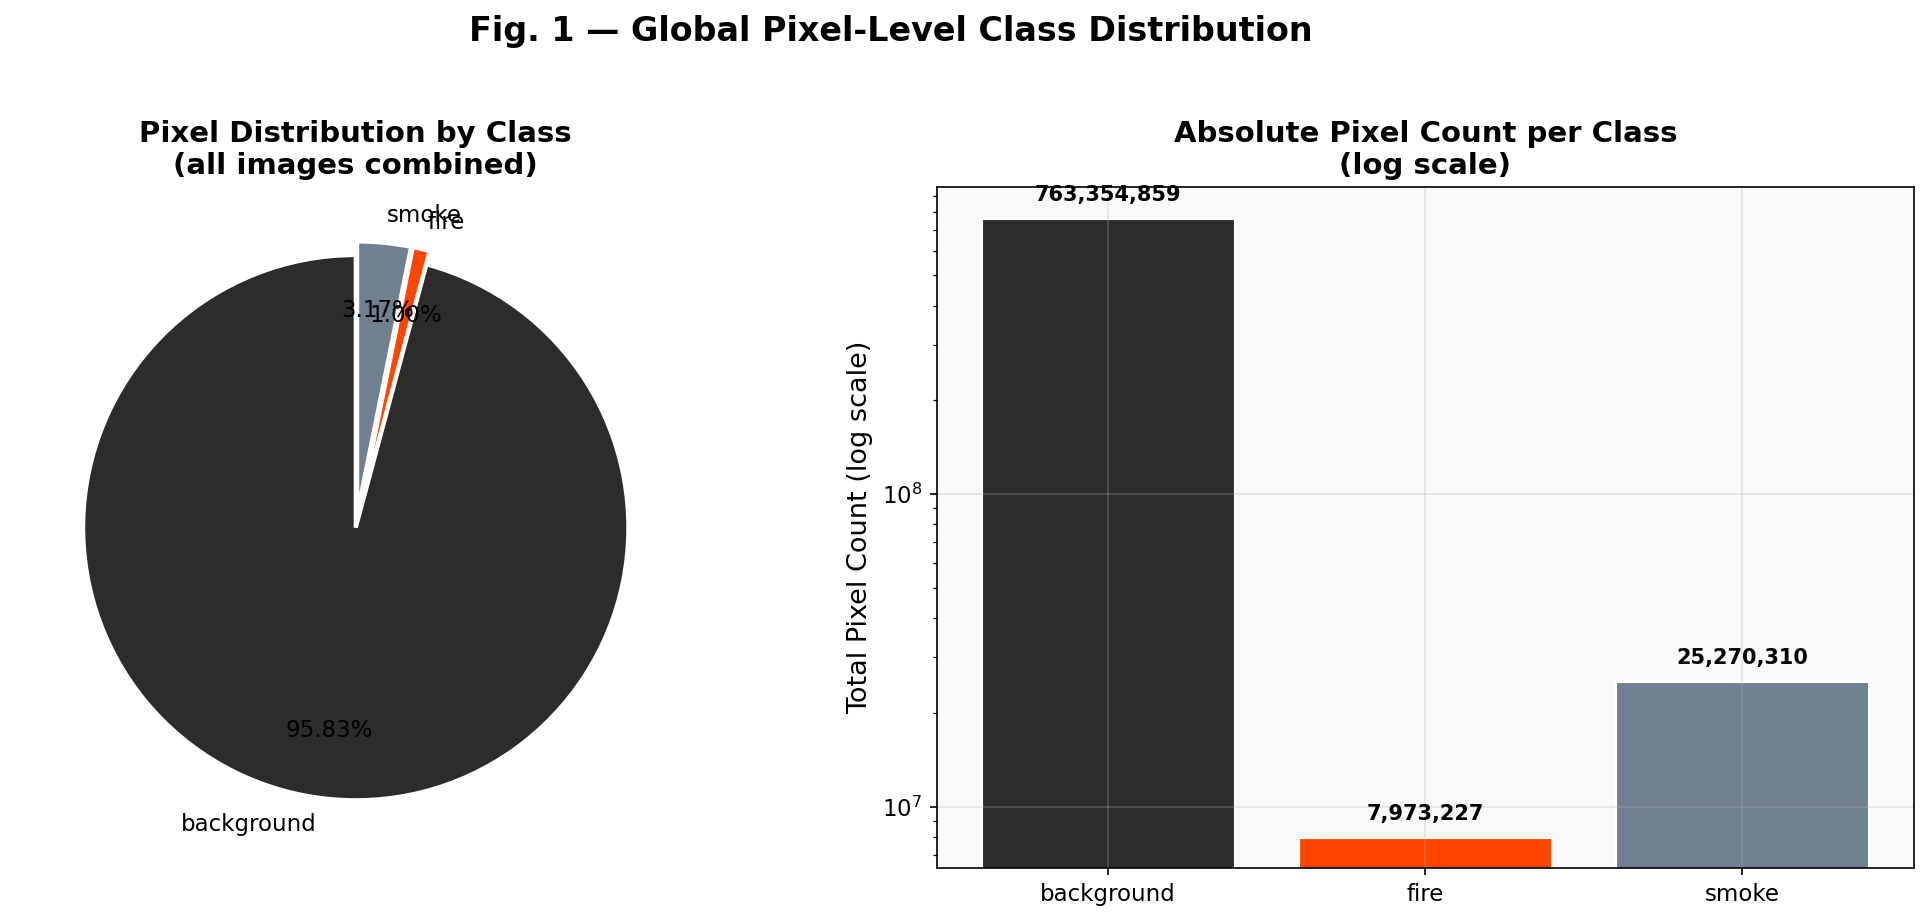

✅ Saved: fig1_class_pixel_distribution.png


In [12]:
# ===== BIỂU ĐỒ 1: Phân bố Pixel theo Lớp (Pie + Bar) =====

total_pixels_per_class = {cname: df[f'px_{cname}'].sum() for cname in CLASS_NAMES
                           if f'px_{cname}' in df.columns}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Fig. 1 — Global Pixel-Level Class Distribution', fontsize=16, fontweight='bold', y=1.02)

# Pie chart
ax = axes[0]
sizes  = list(total_pixels_per_class.values())
labels = list(total_pixels_per_class.keys())
colors_pie = CLASS_COLORS[:len(labels)]
explode = [0.05 if n != 'background' else 0 for n in labels]

wedges, texts, autotexts = ax.pie(
    sizes, labels=labels, autopct='%1.2f%%',
    colors=colors_pie, explode=explode,
    startangle=90, pctdistance=0.75,
    wedgeprops=dict(edgecolor='white', linewidth=2)
)
for t in autotexts: t.set_fontsize(11)
ax.set_title('Pixel Distribution by Class\n(all images combined)', fontweight='bold')

# Bar chart (log scale để thấy lớp nhỏ)
ax2 = axes[1]
bars = ax2.bar(labels, sizes, color=colors_pie, edgecolor='white', linewidth=1.5)
ax2.set_yscale('log')
ax2.set_ylabel('Total Pixel Count (log scale)')
ax2.set_title('Absolute Pixel Count per Class\n(log scale)', fontweight='bold')
for bar, sz in zip(bars, sizes):
    ax2.text(bar.get_x() + bar.get_width()/2., bar.get_height()*1.1,
             f'{sz:,.0f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
fig.savefig(EDA_OUT / 'fig1_class_pixel_distribution.png', bbox_inches='tight', dpi=300)
plt.show()
print('✅ Saved: fig1_class_pixel_distribution.png')

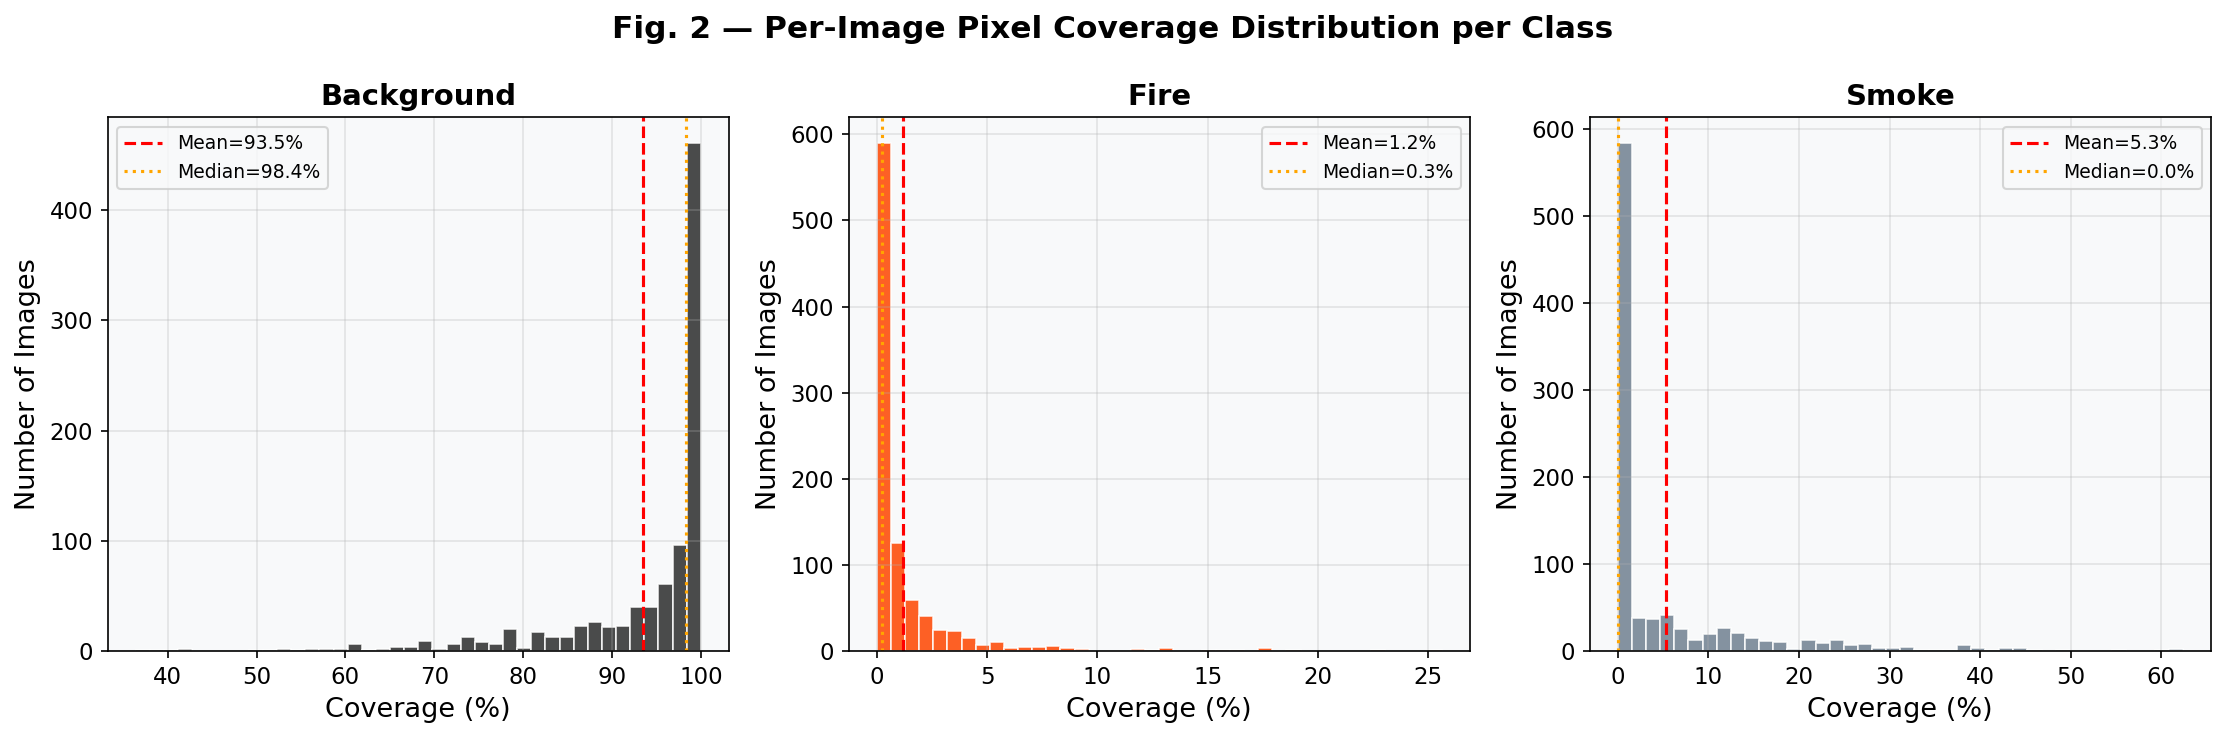

✅ Saved: fig2_coverage_distribution.png


In [13]:
# ===== BIỂU ĐỒ 2: Phân bố Coverage (%) trên từng ảnh =====

fg_classes = [n for n in CLASS_NAMES if n != 'background']
pct_cols   = [f'pct_{n}' for n in CLASS_NAMES if f'pct_{n}' in df.columns]

fig, axes = plt.subplots(1, len(CLASS_NAMES), figsize=(5*len(CLASS_NAMES), 5), sharey=False)
fig.suptitle('Fig. 2 — Per-Image Pixel Coverage Distribution per Class', fontsize=15, fontweight='bold')

if len(CLASS_NAMES) == 1:
    axes = [axes]

for ax, cname, color in zip(axes, CLASS_NAMES, CLASS_COLORS):
    col = f'pct_{cname}'
    if col not in df.columns:
        continue
    data = df[col]
    ax.hist(data, bins=40, color=color, alpha=0.85, edgecolor='white', linewidth=0.8)
    ax.axvline(data.mean(), color='red', linestyle='--', linewidth=1.5, label=f'Mean={data.mean():.1f}%')
    ax.axvline(data.median(), color='orange', linestyle=':', linewidth=1.5, label=f'Median={data.median():.1f}%')
    ax.set_xlabel('Coverage (%)')
    ax.set_ylabel('Number of Images')
    ax.set_title(f'{cname.capitalize()}', fontweight='bold')
    ax.legend(fontsize=9)

plt.tight_layout()
fig.savefig(EDA_OUT / 'fig2_coverage_distribution.png', bbox_inches='tight', dpi=300)
plt.show()
print('✅ Saved: fig2_coverage_distribution.png')

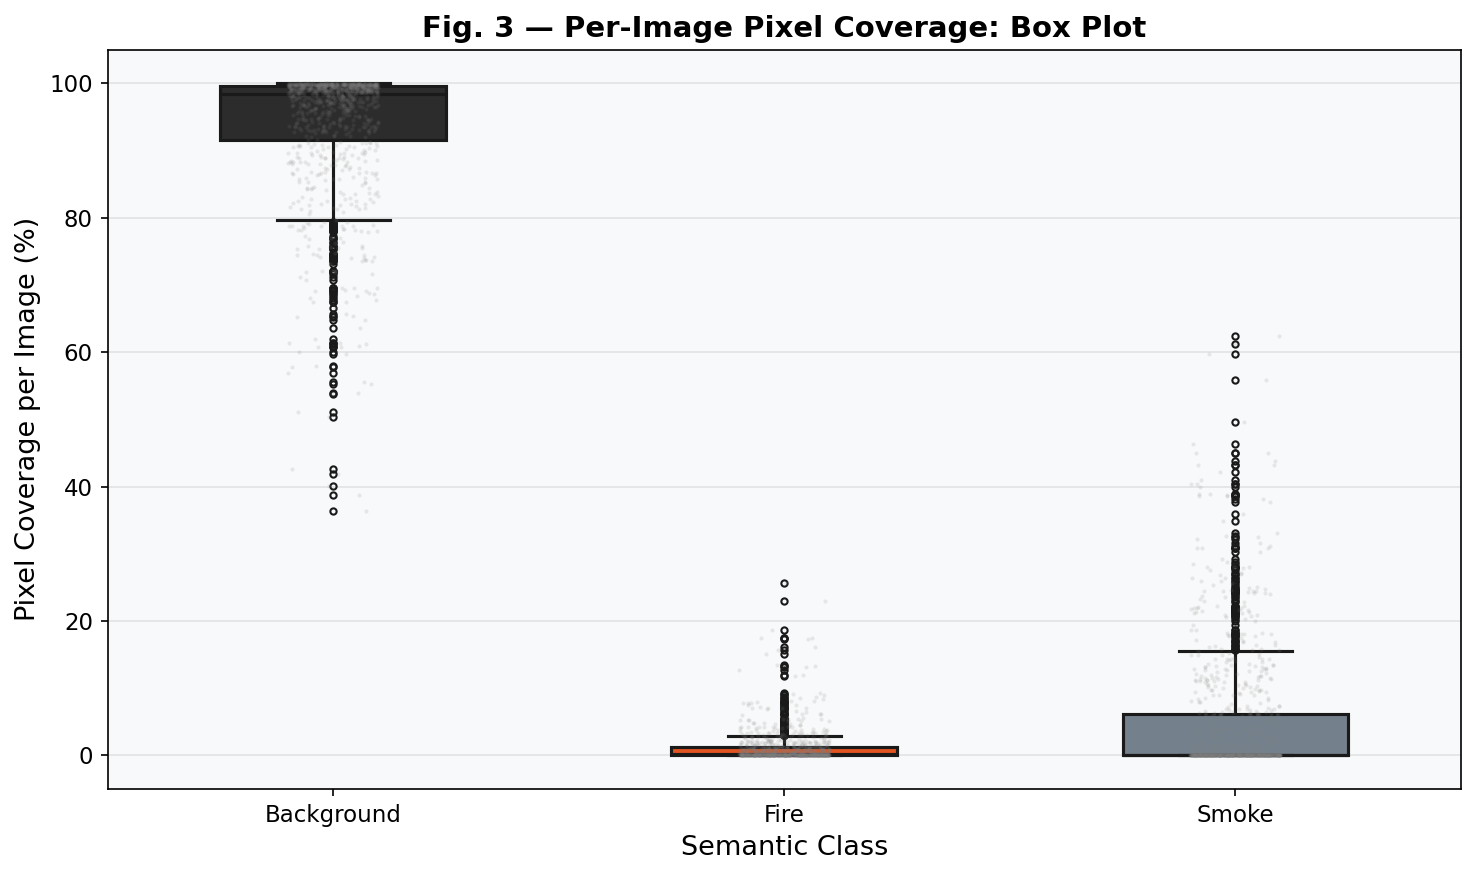

✅ Saved: fig3_coverage_boxplot.png


In [14]:
# ===== BIỂU ĐỒ 3: Box Plot Coverage per Class =====

pct_data = []
for cname in CLASS_NAMES:
    col = f'pct_{cname}'
    if col in df.columns:
        for v in df[col]:
            pct_data.append({'Class': cname.capitalize(), 'Coverage (%)': v})

df_box = pd.DataFrame(pct_data)

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=df_box, x='Class', y='Coverage (%)',
            palette={n.capitalize(): c for n, c in zip(CLASS_NAMES, CLASS_COLORS)},
            width=0.5, linewidth=1.5, fliersize=3, ax=ax)
sns.stripplot(data=df_box, x='Class', y='Coverage (%)',
              alpha=0.15, color='gray', size=2, jitter=True, ax=ax)
ax.set_title('Fig. 3 — Per-Image Pixel Coverage: Box Plot', fontsize=14, fontweight='bold')
ax.set_ylabel('Pixel Coverage per Image (%)')
ax.set_xlabel('Semantic Class')
plt.tight_layout()
fig.savefig(EDA_OUT / 'fig3_coverage_boxplot.png', bbox_inches='tight', dpi=300)
plt.show()
print('✅ Saved: fig3_coverage_boxplot.png')

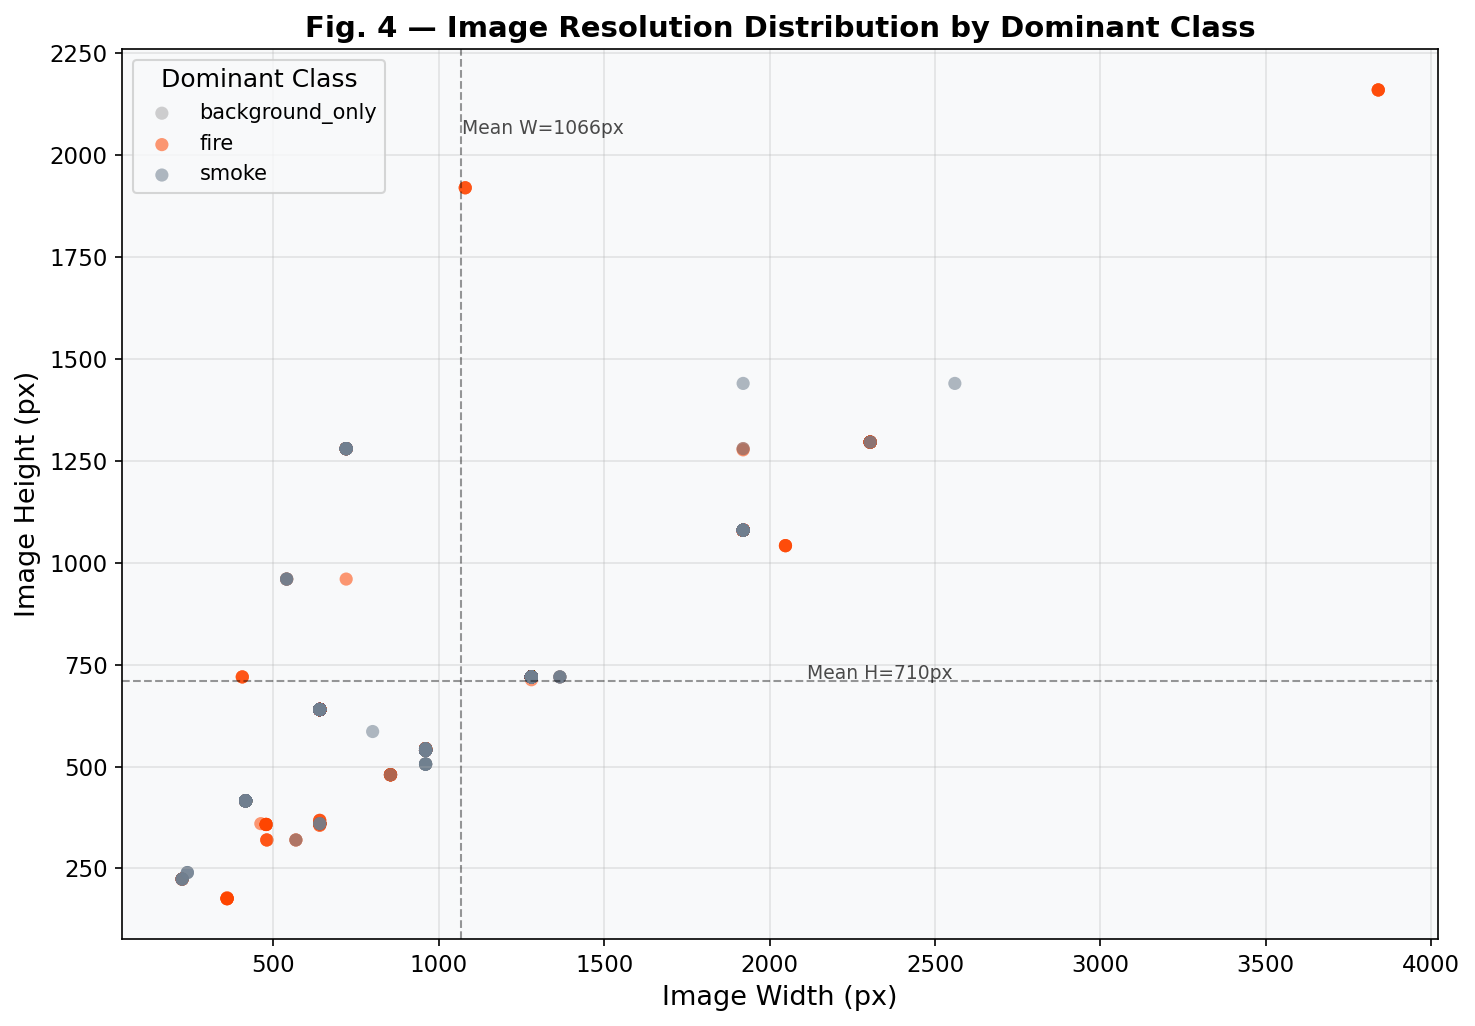

✅ Saved: fig4_resolution_scatter.png


In [17]:
# ===== BIỂU ĐỒ 4: Image Resolution Scatter Plot =====

# Màu mỗi điểm theo lớp dominant (không phải background)
def dominant_fg(row):
    for cname in CLASS_NAMES:
        if cname == 'background': continue
        if row.get(f'has_{cname}', False):
            return cname
    return 'background_only'

df['dominant_class'] = df.apply(dominant_fg, axis=1)

fig, ax = plt.subplots(figsize=(10, 7))

color_map_scatter = {cname: color for cname, color in zip(CLASS_NAMES, CLASS_COLORS)}
color_map_scatter['background_only'] = '#aaaaaa'

for cls, group in df.groupby('dominant_class'):
    ax.scatter(group['width'], group['height'],
               c=color_map_scatter.get(cls, '#aaaaaa'),
               alpha=0.55, s=40, label=cls, edgecolors='none')

ax.set_xlabel('Image Width (px)')
ax.set_ylabel('Image Height (px)')
ax.set_title('Fig. 4 — Image Resolution Distribution by Dominant Class', fontsize=14, fontweight='bold')
ax.legend(title='Dominant Class', fontsize=10)

# Thêm vùng thống kê
ax.axvline(df.width.mean(), color='black', linestyle='--', alpha=0.4, linewidth=1)
ax.axhline(df.height.mean(), color='black', linestyle='--', alpha=0.4, linewidth=1)
ax.text(df.width.mean()+5, df.height.max()*0.95, f'Mean W={df.width.mean():.0f}px',
        fontsize=9, alpha=0.7)
ax.text(df.width.max()*0.55, df.height.mean()+5, f'Mean H={df.height.mean():.0f}px',
        fontsize=9, alpha=0.7)

plt.tight_layout()
fig.savefig(EDA_OUT / 'fig4_resolution_scatter.png', bbox_inches='tight', dpi=300)
plt.show()
print('✅ Saved: fig4_resolution_scatter.png')

🗺️  Building spatial heatmaps:   0%|          | 0/935 [00:00<?, ?it/s]

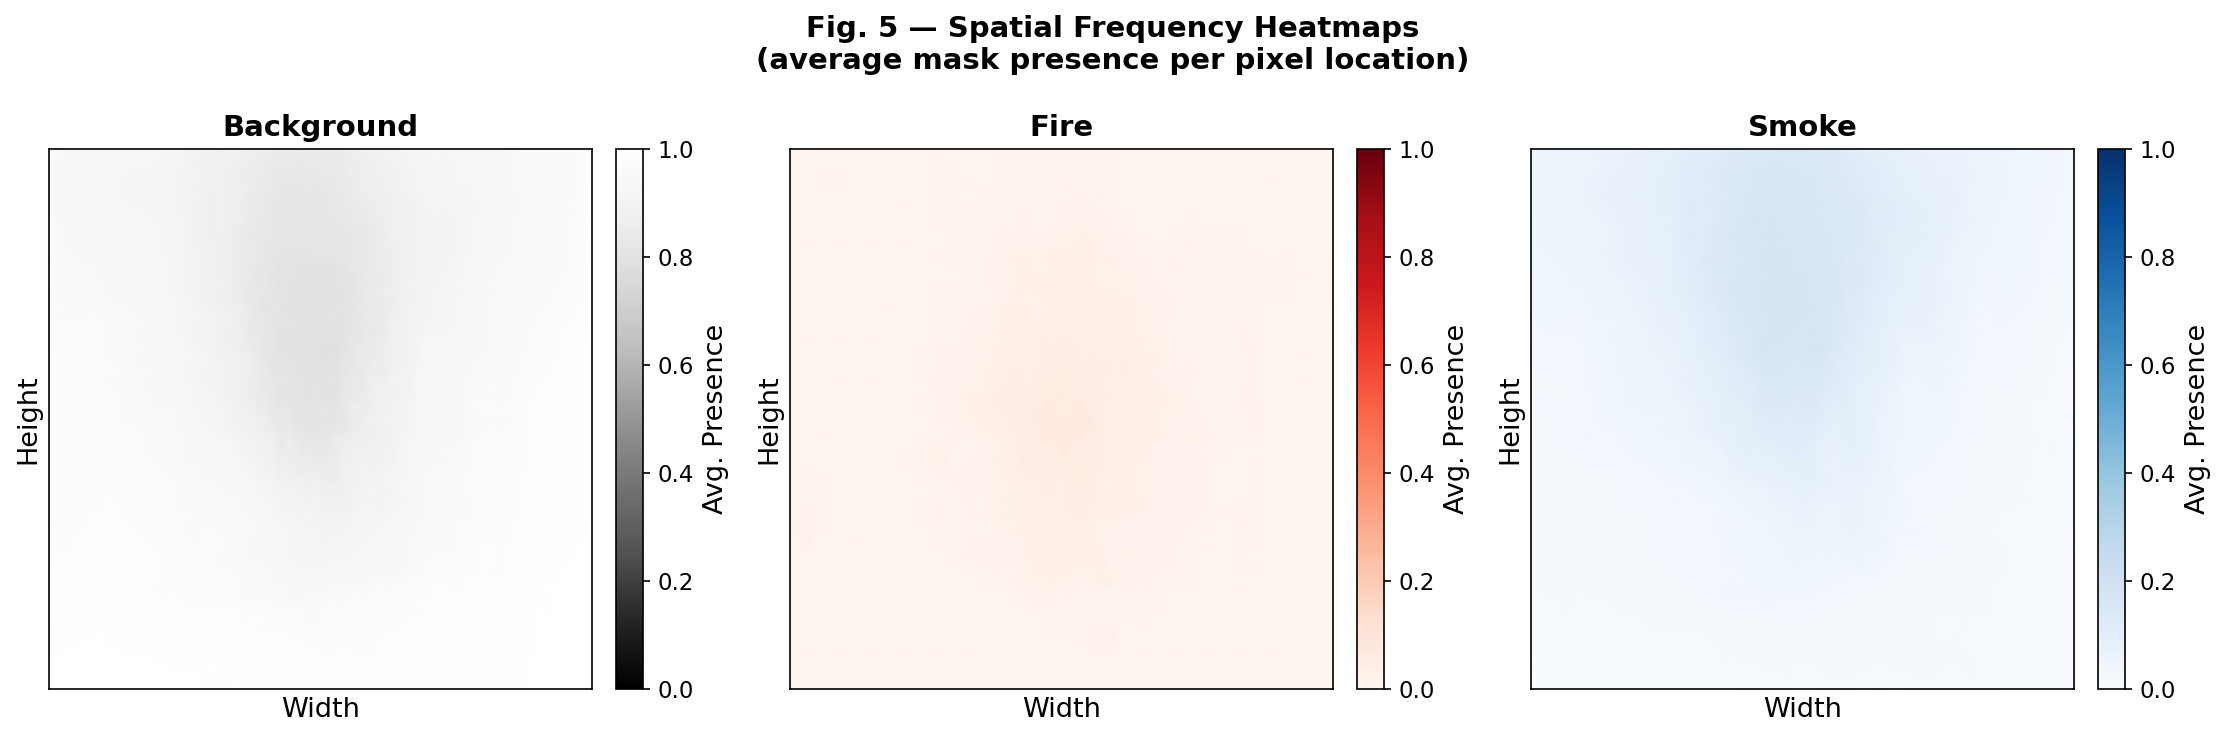

✅ Saved: fig5_spatial_heatmaps.png


In [18]:
# ===== BIỂU ĐỒ 5: Spatial Heatmap — Nơi Fire/Smoke thường xuất hiện =====
# Resize tất cả mask về cùng kích thước, cộng dồn → heatmap trung bình

TARGET_SIZE = (256, 256)  # resize để tính nhanh

# Tạo accumulator cho mỗi lớp
accumulators = {cid: np.zeros(TARGET_SIZE, dtype=np.float64)
                for cid in range(N_CLASSES)}
n_processed = 0

for base in tqdm(paired_list, desc='🗺️  Building spatial heatmaps'):
    mask_path = masks[base]
    try:
        class_arr = mask_to_classmap(mask_path, MASK_MODE, CLASS_MAP)
        for cid in range(N_CLASSES):
            layer = (class_arr == cid).astype(np.float32)
            layer_resized = cv2.resize(layer, TARGET_SIZE[::-1], interpolation=cv2.INTER_AREA)
            accumulators[cid] += layer_resized
        n_processed += 1
    except:
        continue

# Normalize
for cid in range(N_CLASSES):
    accumulators[cid] /= (n_processed + 1e-8)

# Plot heatmaps
n_show = min(N_CLASSES, 4)
fig, axes = plt.subplots(1, n_show, figsize=(5*n_show, 5))
fig.suptitle('Fig. 5 — Spatial Frequency Heatmaps\n(average mask presence per pixel location)',
             fontsize=14, fontweight='bold')

if n_show == 1: axes = [axes]

for ax, (cid, cname, ccolor) in zip(axes, [(i, n, c) for i,(n,c) in enumerate(zip(CLASS_NAMES, CLASS_COLORS))]):
    hm = accumulators[cid]
    cmap_name = 'Reds' if cname == 'fire' else ('Greys_r' if cname == 'background' else 'Blues')
    im = ax.imshow(hm, cmap=cmap_name, vmin=0, vmax=1, aspect='auto')
    ax.set_title(f'{cname.capitalize()}', fontweight='bold')
    ax.set_xlabel('Width')
    ax.set_ylabel('Height')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='Avg. Presence')
    ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
fig.savefig(EDA_OUT / 'fig5_spatial_heatmaps.png', bbox_inches='tight', dpi=300)
plt.show()
print('✅ Saved: fig5_spatial_heatmaps.png')

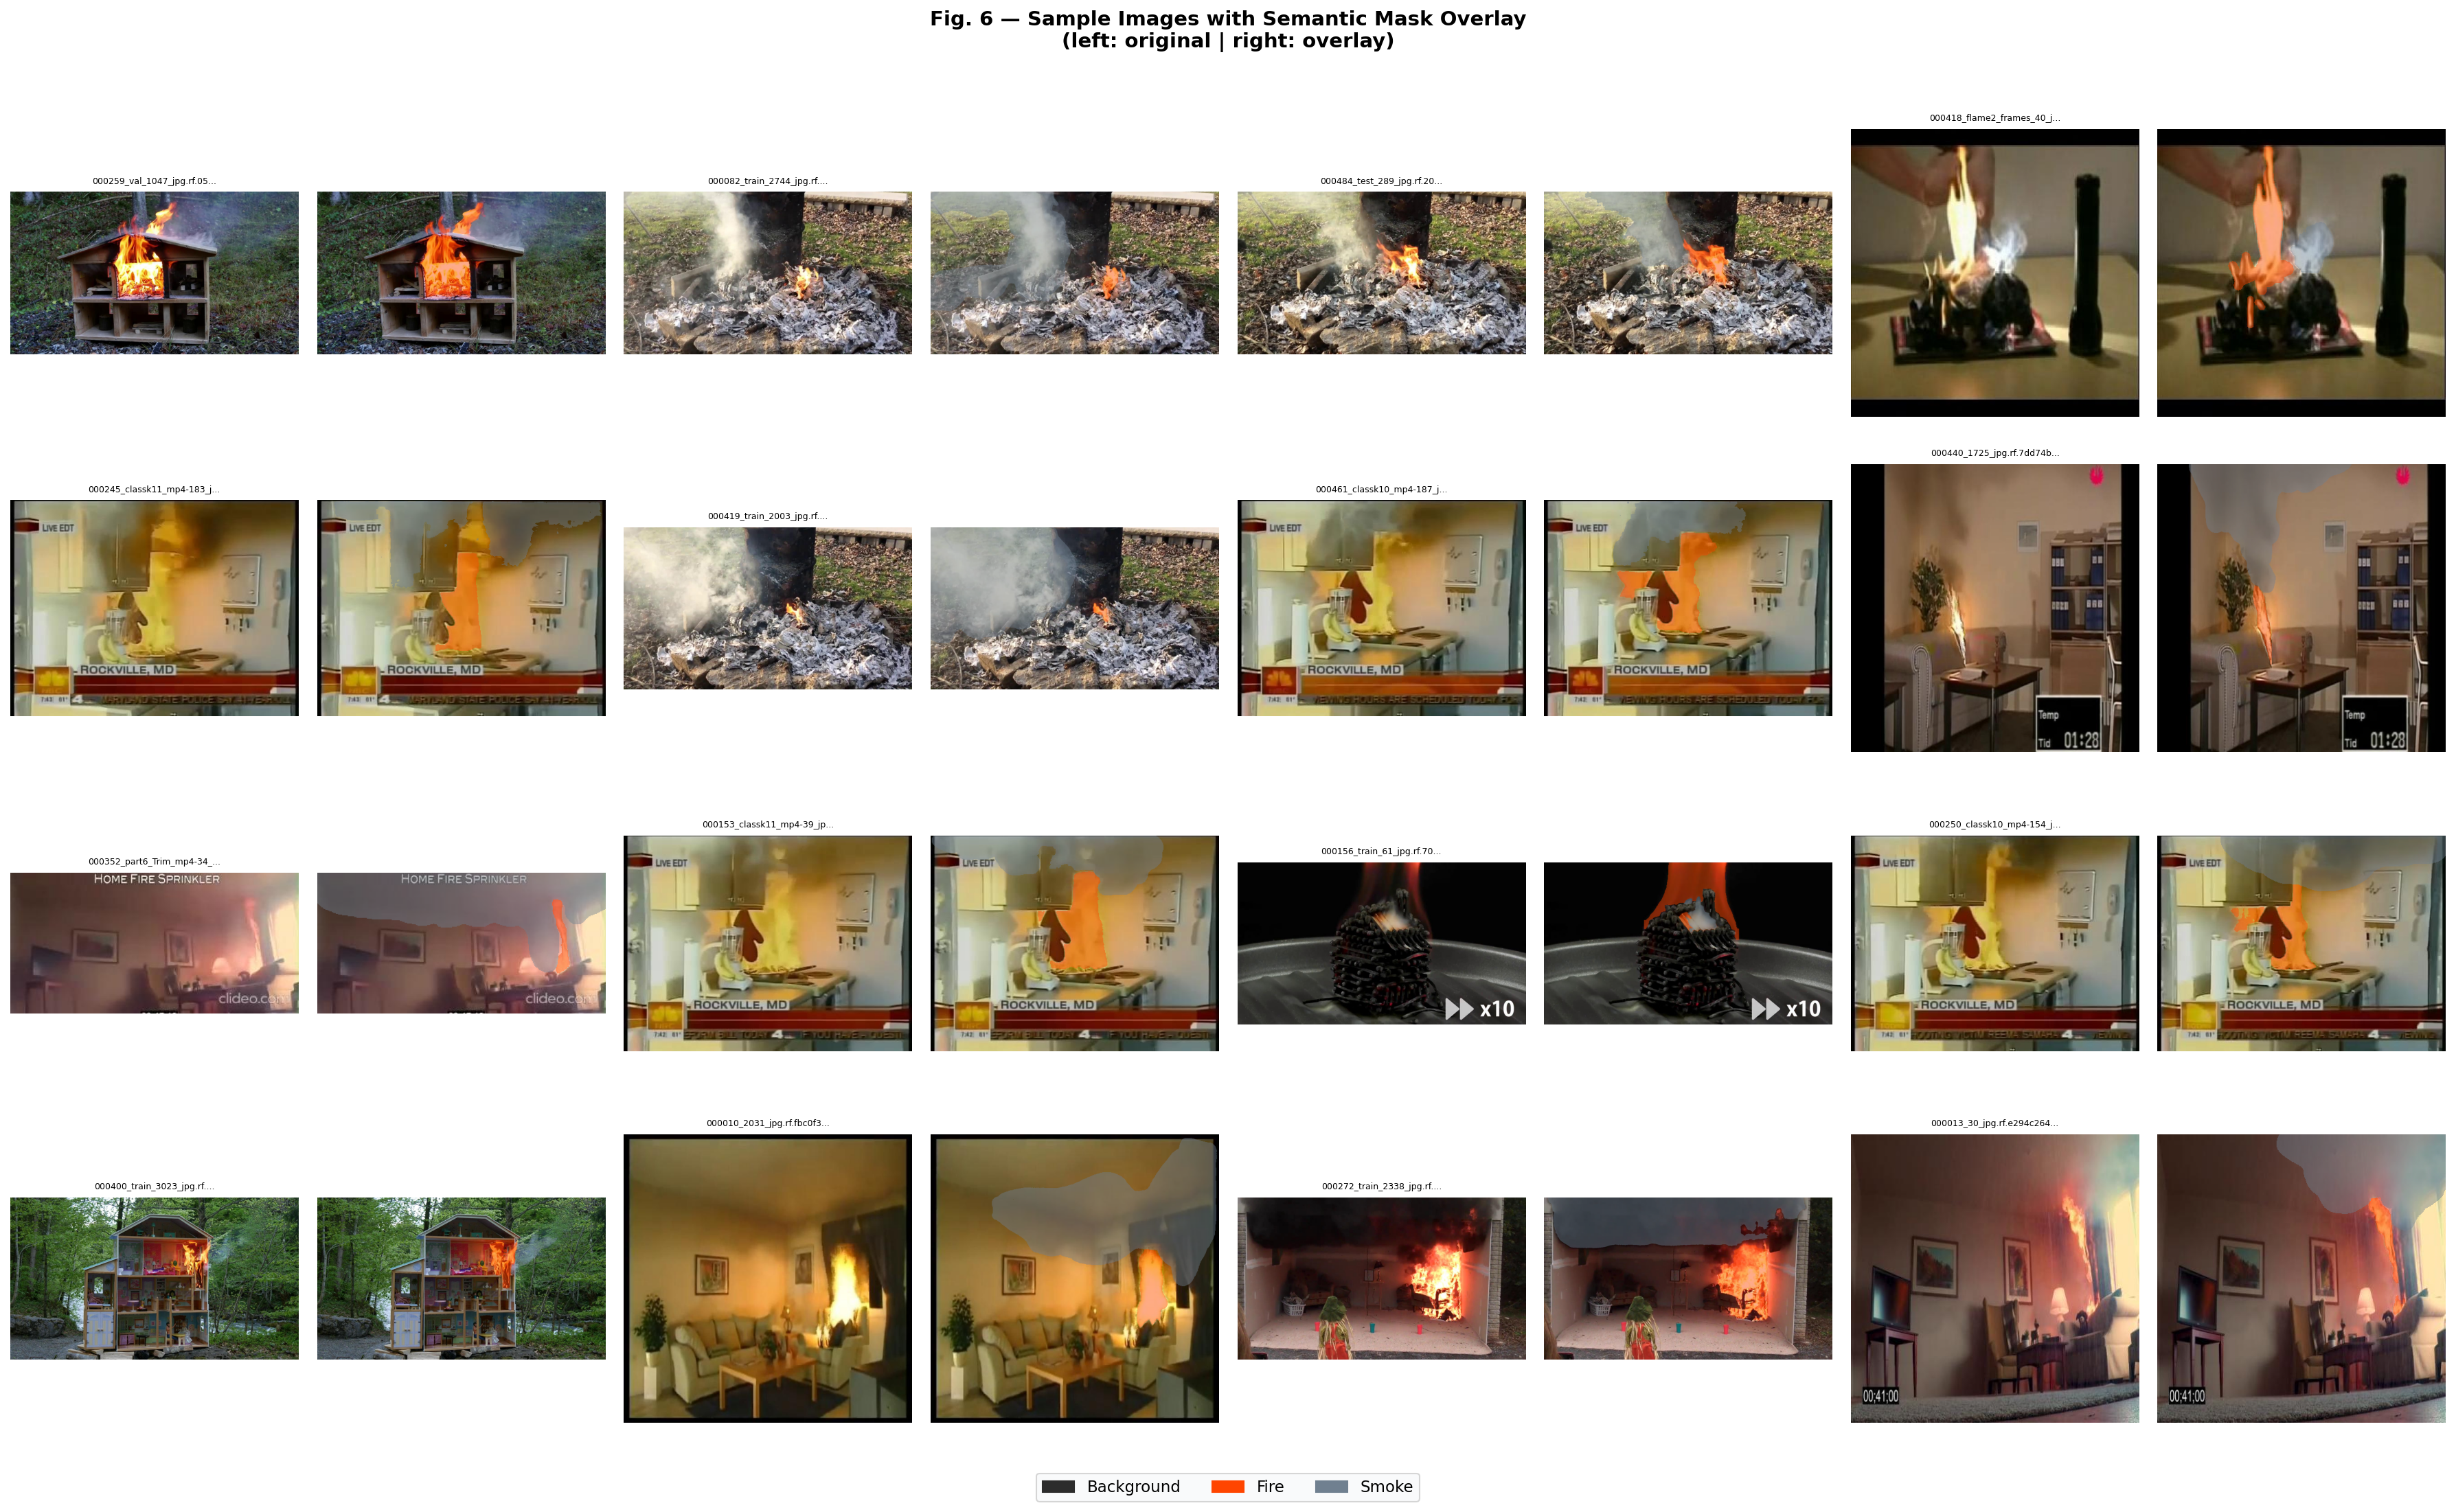

✅ Saved: fig6_sample_grid_overlay.png


In [19]:
# ===== BIỂU ĐỒ 6: Sample Grid — Ảnh + Mask Overlay =====

def overlay_mask_on_image(img_path, mask_path, alpha=0.45):
    """Tạo overlay ảnh + mask (màu sắc theo lớp)."""
    img = np.array(Image.open(img_path).convert('RGB'))
    class_arr = mask_to_classmap(mask_path, MASK_MODE, CLASS_MAP)

    overlay = img.copy().astype(np.float32)
    for cid, (cname, ccolor) in enumerate(zip(CLASS_NAMES, CLASS_COLORS)):
        if cname == 'background': continue
        r = int(ccolor[1:3], 16)
        g = int(ccolor[3:5], 16)
        b = int(ccolor[5:7], 16)
        mask_layer = (class_arr == cid)
        overlay[mask_layer] = overlay[mask_layer] * (1 - alpha) + np.array([r,g,b]) * alpha

    return img, overlay.astype(np.uint8), class_arr


# Chọn mẫu: ưu tiên ảnh có cả fire và smoke
def pick_diverse_samples(df, n=16):
    samples = []
    fg_classes = [n for n in CLASS_NAMES if n != 'background']

    # Ưu tiên ảnh có nhiều lớp nhất
    sorted_df = df.sort_values('n_fg_classes', ascending=False)
    for _, row in sorted_df.iterrows():
        samples.append(row['basename'])
        if len(samples) >= n:
            break
    return samples[:n]


sample_bases = pick_diverse_samples(df, n=16)
NCOLS, NROWS = 4, 4

fig, axes = plt.subplots(NROWS, NCOLS*2, figsize=(NCOLS*6, NROWS*3.5))
fig.suptitle('Fig. 6 — Sample Images with Semantic Mask Overlay\n(left: original | right: overlay)',
             fontsize=14, fontweight='bold', y=1.01)

legend_patches = [mpatches.Patch(color=c, label=n.capitalize())
                  for n, c in zip(CLASS_NAMES, CLASS_COLORS)]

for idx, base in enumerate(sample_bases):
    row_i = idx // NCOLS
    col_i = idx  % NCOLS

    ax_orig    = axes[row_i][col_i*2]
    ax_overlay = axes[row_i][col_i*2 + 1]

    try:
        img, ov, _ = overlay_mask_on_image(images[base], masks[base])
        ax_orig.imshow(img)
        ax_overlay.imshow(ov)
    except Exception as e:
        ax_orig.text(0.5, 0.5, f'Error', ha='center', va='center', transform=ax_orig.transAxes)
        ax_overlay.text(0.5, 0.5, f'Error', ha='center', va='center', transform=ax_overlay.transAxes)

    short = base[:25] + '...' if len(base) > 25 else base
    ax_orig.set_title(f'{short}', fontsize=6)
    ax_orig.axis('off')
    ax_overlay.axis('off')

fig.legend(handles=legend_patches, loc='lower center', ncol=N_CLASSES,
           bbox_to_anchor=(0.5, -0.03), fontsize=11)
plt.tight_layout()
fig.savefig(EDA_OUT / 'fig6_sample_grid_overlay.png', bbox_inches='tight', dpi=200)
plt.show()
print('✅ Saved: fig6_sample_grid_overlay.png')

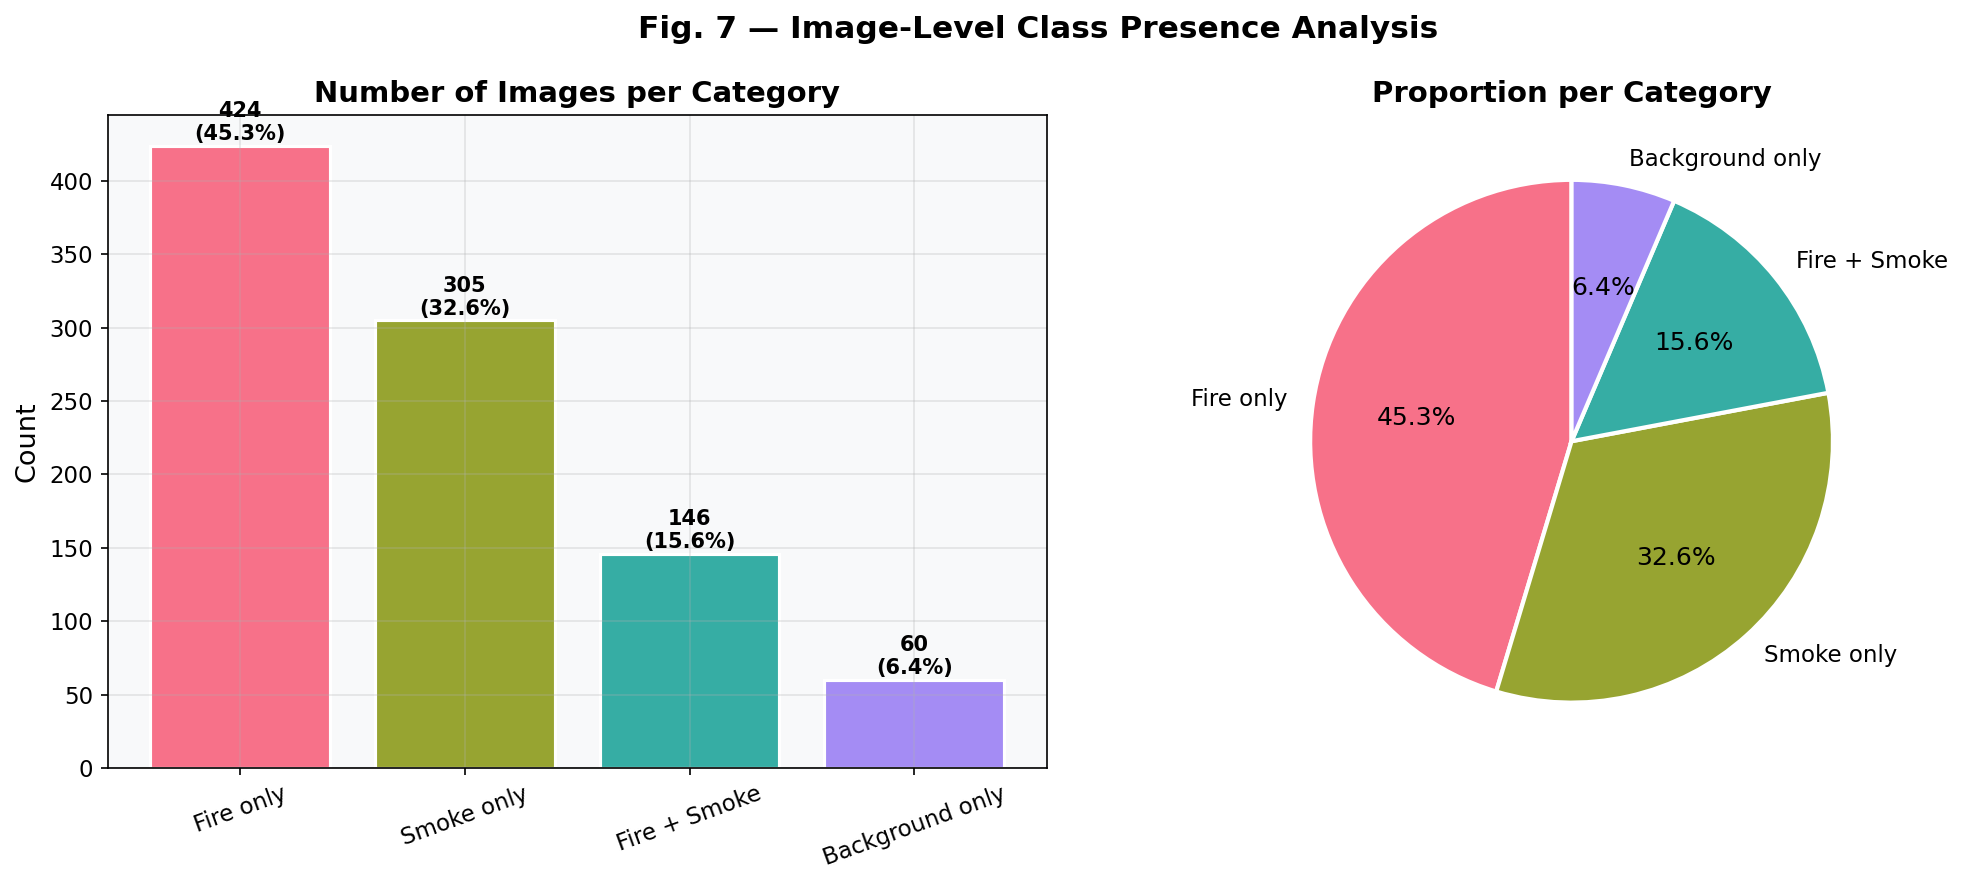

✅ Saved: fig7_class_presence.png


In [20]:
# ===== BIỂU ĐỒ 7: Image-Level Class Presence (Venn / Stacked Bar) =====

fg_classes = [n for n in CLASS_NAMES if n != 'background']

# Phân loại từng ảnh
def categorize_image(row):
    present = [n for n in fg_classes if row.get(f'has_{n}', False)]
    if not present:
        return 'Background only'
    if len(present) == len(fg_classes) and len(fg_classes) > 1:
        return ' + '.join(n.capitalize() for n in present)
    return present[0].capitalize() + ' only'

df['category'] = df.apply(categorize_image, axis=1)
cat_counts = df['category'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Fig. 7 — Image-Level Class Presence Analysis', fontsize=15, fontweight='bold')

# Bar chart
ax = axes[0]
bars = ax.bar(cat_counts.index, cat_counts.values,
              color=sns.color_palette('husl', len(cat_counts)),
              edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, cat_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 1,
            f'{val}\n({100*val/len(df):.1f}%)',
            ha='center', va='bottom', fontsize=10, fontweight='bold')
ax.set_title('Number of Images per Category', fontweight='bold')
ax.set_ylabel('Count')
ax.tick_params(axis='x', rotation=20)

# Pie chart
ax2 = axes[1]
ax2.pie(cat_counts.values, labels=cat_counts.index,
        autopct='%1.1f%%', startangle=90,
        colors=sns.color_palette('husl', len(cat_counts)),
        wedgeprops=dict(edgecolor='white', linewidth=2))
ax2.set_title('Proportion per Category', fontweight='bold')

plt.tight_layout()
fig.savefig(EDA_OUT / 'fig7_class_presence.png', bbox_inches='tight', dpi=300)
plt.show()
print('✅ Saved: fig7_class_presence.png')

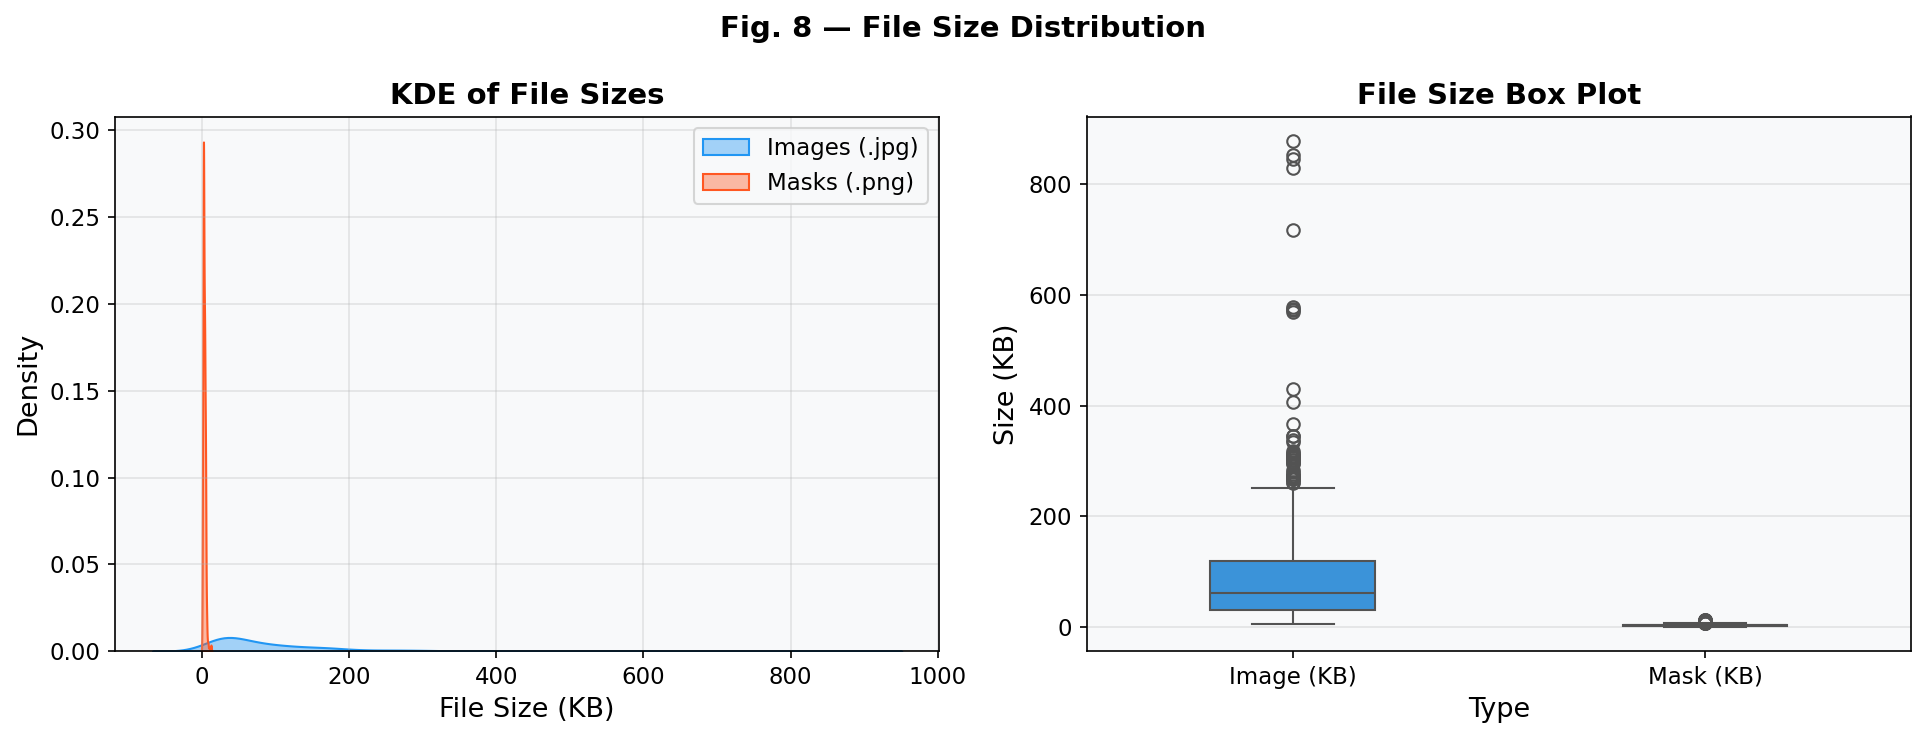

✅ Saved: fig8_file_size_distribution.png


In [21]:
# ===== BIỂU ĐỒ 8: File Size Distribution (Image vs Mask) =====

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Fig. 8 — File Size Distribution', fontsize=14, fontweight='bold')

# KDE plot
ax = axes[0]
sns.kdeplot(df['img_size_kb'], label='Images (.jpg)', color='#2196F3', fill=True, alpha=0.4, ax=ax)
sns.kdeplot(df['mask_size_kb'], label='Masks (.png)', color='#FF5722', fill=True, alpha=0.4, ax=ax)
ax.set_xlabel('File Size (KB)')
ax.set_ylabel('Density')
ax.set_title('KDE of File Sizes', fontweight='bold')
ax.legend()

# Box plot
ax2 = axes[1]
size_df = pd.DataFrame({
    'Image (KB)': df['img_size_kb'],
    'Mask (KB)' : df['mask_size_kb']
})
size_df_melt = size_df.melt(var_name='Type', value_name='Size (KB)')
sns.boxplot(data=size_df_melt, x='Type', y='Size (KB)',
            palette=['#2196F3', '#FF5722'], ax=ax2, width=0.4)
ax2.set_title('File Size Box Plot', fontweight='bold')

plt.tight_layout()
fig.savefig(EDA_OUT / 'fig8_file_size_distribution.png', bbox_inches='tight', dpi=300)
plt.show()
print('✅ Saved: fig8_file_size_distribution.png')

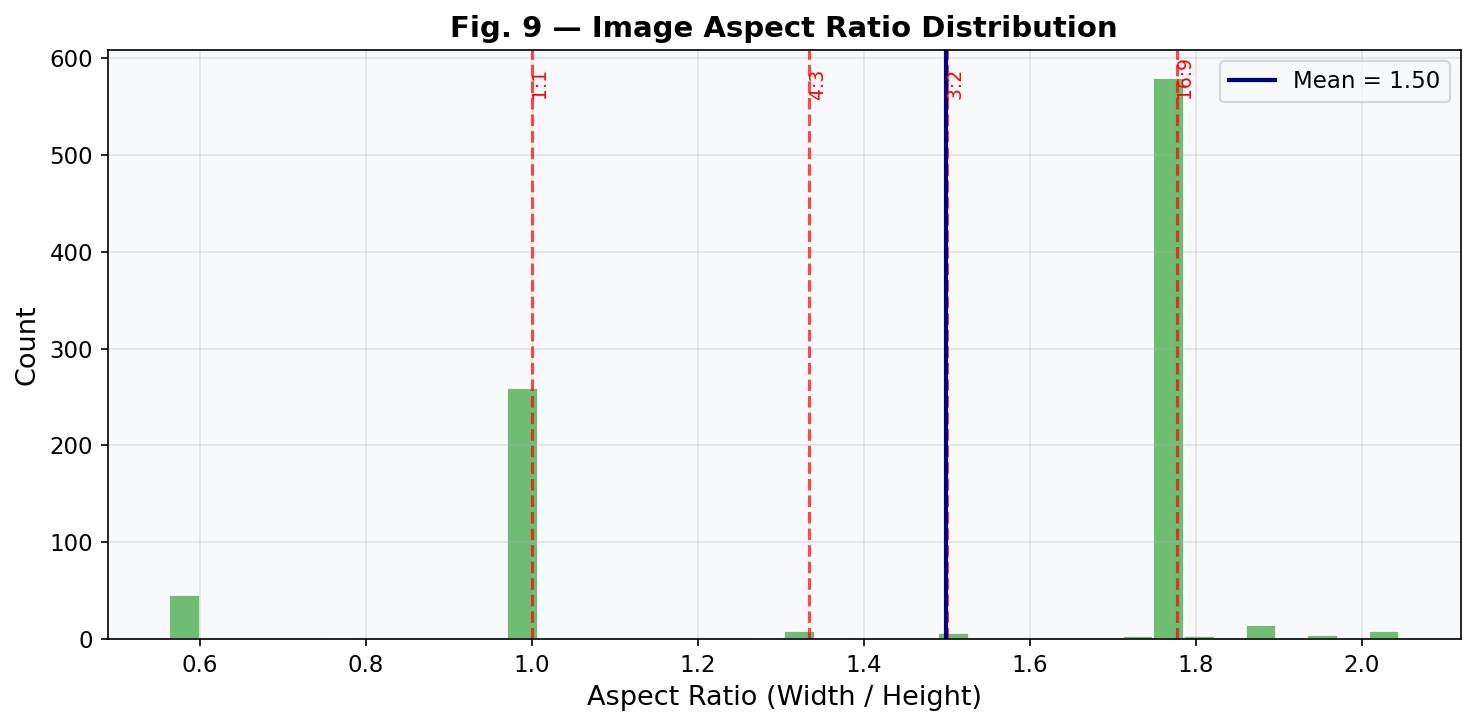

✅ Saved: fig9_aspect_ratio.png


In [22]:
# ===== BIỂU ĐỒ 9: Aspect Ratio Distribution =====

fig, ax = plt.subplots(figsize=(10, 5))
common_ratios = {1.0: '1:1', 4/3: '4:3', 16/9: '16:9', 3/2: '3:2'}

sns.histplot(df['aspect_ratio'], bins=40, color='#4CAF50', alpha=0.8,
             edgecolor='white', linewidth=0.8, ax=ax)

for ratio, label in common_ratios.items():
    ax.axvline(ratio, color='red', linestyle='--', alpha=0.7, linewidth=1.5)
    ax.text(ratio, ax.get_ylim()[1]*0.9, f'  {label}', fontsize=9, color='red', rotation=90)

ax.axvline(df.aspect_ratio.mean(), color='navy', linewidth=2,
           label=f'Mean = {df.aspect_ratio.mean():.2f}')
ax.set_xlabel('Aspect Ratio (Width / Height)')
ax.set_ylabel('Count')
ax.set_title('Fig. 9 — Image Aspect Ratio Distribution', fontsize=14, fontweight='bold')
ax.legend()

plt.tight_layout()
fig.savefig(EDA_OUT / 'fig9_aspect_ratio.png', bbox_inches='tight', dpi=300)
plt.show()
print('✅ Saved: fig9_aspect_ratio.png')

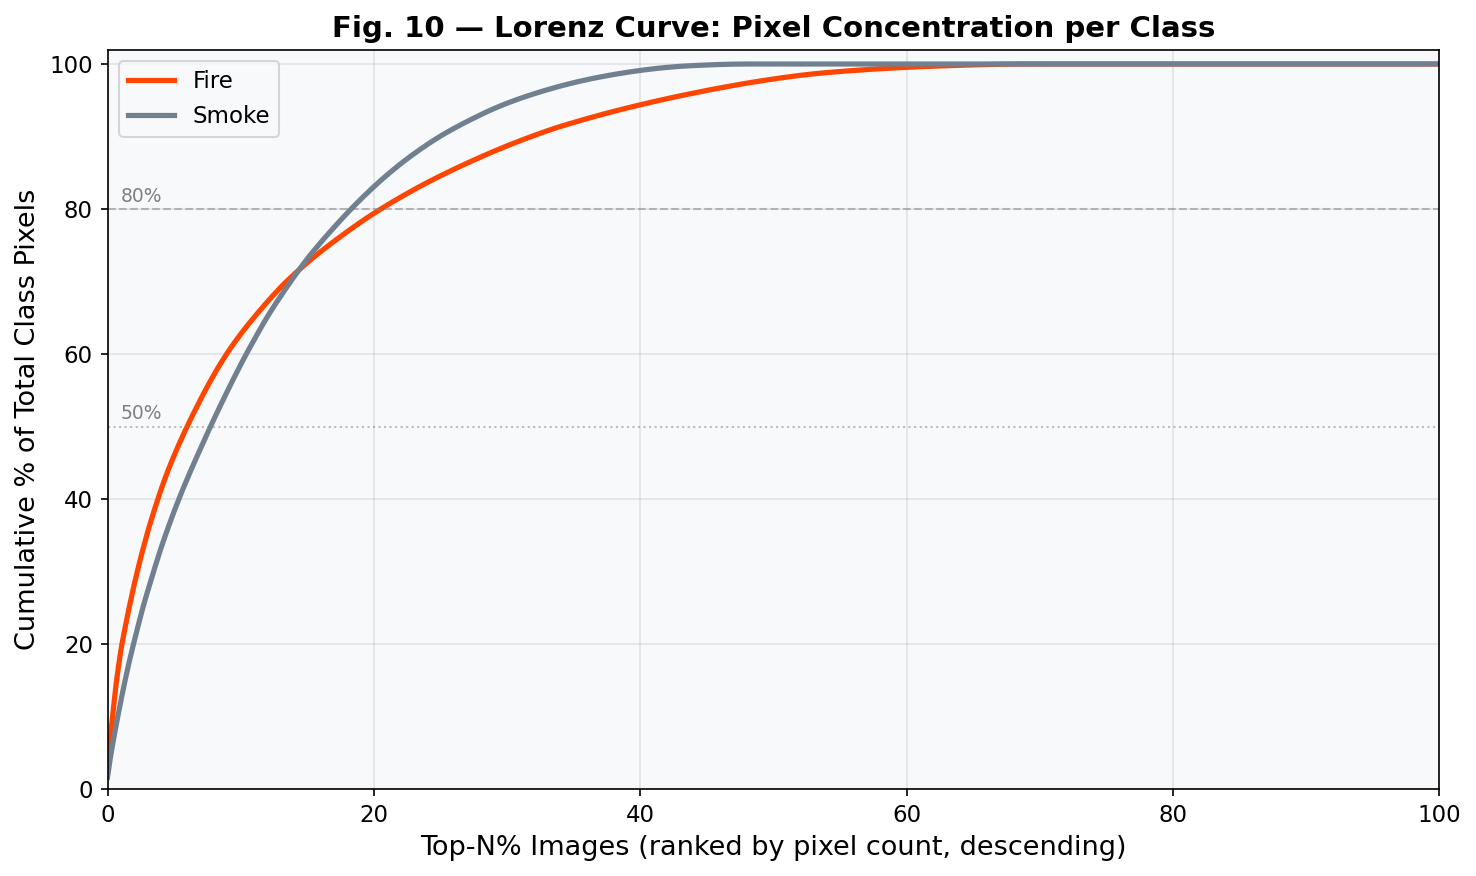

✅ Saved: fig10_lorenz_curve.png


In [23]:
# ===== BIỂU ĐỒ 10: Cumulative Coverage Curve =====
# Top-N% ảnh chứa bao nhiêu % tổng pixel foreground?

fig, ax = plt.subplots(figsize=(10, 6))

for cname, color in zip(CLASS_NAMES, CLASS_COLORS):
    col = f'px_{cname}'
    if col not in df.columns or cname == 'background': continue
    sorted_vals = df[col].sort_values(ascending=False).values
    cumsum = np.cumsum(sorted_vals)
    total  = cumsum[-1] if cumsum[-1] > 0 else 1
    x = np.linspace(0, 100, len(cumsum))
    y = 100 * cumsum / total
    ax.plot(x, y, label=cname.capitalize(), color=color, linewidth=2.5)

ax.axhline(80, color='gray', linestyle='--', alpha=0.5, linewidth=1)
ax.axhline(50, color='gray', linestyle=':',  alpha=0.5, linewidth=1)
ax.text(1, 81, '80%', fontsize=9, color='gray')
ax.text(1, 51, '50%', fontsize=9, color='gray')

ax.set_xlabel('Top-N% Images (ranked by pixel count, descending)')
ax.set_ylabel('Cumulative % of Total Class Pixels')
ax.set_title('Fig. 10 — Lorenz Curve: Pixel Concentration per Class',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.set_xlim(0, 100)
ax.set_ylim(0, 102)

plt.tight_layout()
fig.savefig(EDA_OUT / 'fig10_lorenz_curve.png', bbox_inches='tight', dpi=300)
plt.show()
print('✅ Saved: fig10_lorenz_curve.png')

In [24]:
# ===== BẢNG TỔNG KẾT EDA =====

print('='*65)
print('📋  BẢNG TỔNG KẾT EDA — PUBLICATION SUMMARY')
print('='*65)
print(f'  Total images (paired)  : {len(df)}')
print(f'  Image dimensions       :')
print(f'    Min : {df.width.min()}×{df.height.min()} px')
print(f'    Max : {df.width.max()}×{df.height.max()} px')
print(f'    Mean: {df.width.mean():.0f}×{df.height.mean():.0f} px')
print(f'  Aspect ratio mean      : {df.aspect_ratio.mean():.3f}')
print(f'  Image file size (KB)   : mean={df.img_size_kb.mean():.1f}, std={df.img_size_kb.std():.1f}')
print()
print('  Pixel-level class distribution (global):')
for cname in CLASS_NAMES:
    col = f'px_{cname}'
    if col not in df.columns: continue
    total_px = df[col].sum()
    grand_total = sum(df[f'px_{n}'].sum() for n in CLASS_NAMES if f'px_{n}' in df.columns)
    pct = 100 * total_px / grand_total
    print(f'    {cname:15s}: {total_px:>15,.0f} px ({pct:.2f}%)')

print()
print('  Image-level presence:')
for cname in CLASS_NAMES:
    if cname == 'background': continue
    if f'has_{cname}' in df.columns:
        n_has = df[f'has_{cname}'].sum()
        print(f'    Has {cname:10s}: {n_has}/{len(df)} ({100*n_has/len(df):.1f}%)')

print()
print('  Coverage per image (when present):')
for cname in CLASS_NAMES:
    if cname == 'background': continue
    col = f'pct_{cname}'
    if col not in df.columns: continue
    present = df[df[col] > 0][col]
    if len(present) == 0: continue
    print(f'    {cname:15s}: mean={present.mean():.2f}%, median={present.median():.2f}%, '
          f'std={present.std():.2f}%')

print(f'\n📁 Tất cả biểu đồ đã lưu tại: {EDA_OUT}')
print('='*65)

📋  BẢNG TỔNG KẾT EDA — PUBLICATION SUMMARY
  Total images (paired)  : 935
  Image dimensions       :
    Min : 224×176 px
    Max : 3840×2160 px
    Mean: 1066×710 px
  Aspect ratio mean      : 1.500
  Image file size (KB)   : mean=91.5, std=95.6

  Pixel-level class distribution (global):
    background     :     763,354,859 px (95.83%)
    fire           :       7,973,227 px (1.00%)
    smoke          :      25,270,310 px (3.17%)

  Image-level presence:
    Has fire      : 570/935 (61.0%)
    Has smoke     : 451/935 (48.2%)

  Coverage per image (when present):
    fire           : mean=1.72%, median=0.74%, std=2.90%
    smoke          : mean=10.94%, median=6.48%, std=11.66%

📁 Tất cả biểu đồ đã lưu tại: E:\NCKH\Code\Fire_Smoke_Early-Detection\docs\eda_figures


---
# ⚖️ PHASE 3 — Xử lý Mất cân bằng & Augmentation Pipeline

## 3.1 — Tính Class Weights để xử lý mất cân bằng

In [25]:
# ===== PHASE 3.1: Tính Class Weights =====
# Median frequency balancing (phổ biến trong segmentation)

# Tổng pixel mỗi lớp
px_totals = np.array([
    df[f'px_{cname}'].sum() for cname in CLASS_NAMES
    if f'px_{cname}' in df.columns
], dtype=np.float64)

freq = px_totals / px_totals.sum()  # tần suất mỗi lớp
median_freq = np.median(freq[freq > 0])

# Median Frequency Weighting: w_c = median_freq / freq_c
weights_median = np.where(freq > 0, median_freq / freq, 0.0)

# Inverse frequency weighting
weights_inv = np.where(freq > 0, 1.0 / (freq + 1e-8), 0.0)
weights_inv = weights_inv / weights_inv.sum() * N_CLASSES  # normalize

print('='*55)
print('CLASS WEIGHT ANALYSIS')
print('='*55)
print(f'{"Class":<15} {"Pixels":>12} {"Freq(%)":>8} {"W_median":>10} {"W_inv":>10}')
print('-'*55)
for i, cname in enumerate(CLASS_NAMES):
    if f'px_{cname}' not in df.columns: continue
    print(f'{cname:<15} {int(px_totals[i]):>12,} {freq[i]*100:>7.3f}%  '
          f'{weights_median[i]:>9.4f}  {weights_inv[i]:>9.4f}')

print()
print('Gợi ý dùng Median Frequency Weighting:')
print(f'  class_weights = {list(np.round(weights_median, 4))}')
print()

# Imbalance ratio
if len(freq) > 1 and freq.min() > 0:
    ratio = freq.max() / freq.min()
    print(f'  ⚠️  Imbalance ratio (max/min freq) = {ratio:.1f}x')
    if ratio > 10:
        print('  → Mất cân bằng NGHIÊM TRỌNG! Cần dùng Focal Loss + Oversampling')
    elif ratio > 5:
        print('  → Mất cân bằng VỪA PHẢI. Nên dùng Weighted CE Loss')
    else:
        print('  → Mất cân bằng NHẸ. Weighted CE là đủ')

CLASS WEIGHT ANALYSIS
Class                 Pixels  Freq(%)   W_median      W_inv
-------------------------------------------------------
background       763,354,859  95.827%     0.0331     0.0236
fire               7,973,227   1.001%     3.1694     2.2625
smoke             25,270,310   3.172%     1.0000     0.7139

Gợi ý dùng Median Frequency Weighting:
  class_weights = [np.float64(0.0331), np.float64(3.1694), np.float64(1.0)]

  ⚠️  Imbalance ratio (max/min freq) = 95.7x
  → Mất cân bằng NGHIÊM TRỌNG! Cần dùng Focal Loss + Oversampling


In [26]:
# ===== PHASE 3.2: Focal Loss Implementation =====

import torch
import torch.nn as nn
import torch.nn.functional as F


class FocalLoss(nn.Module):
    """
    Focal Loss cho Semantic Segmentation.
    Giảm thiểu ảnh hưởng của background dễ phân loại,
    tập trung vào fire/smoke khó phân loại.
    """
    def __init__(self, alpha=None, gamma=2.0, ignore_index=255, reduction='mean'):
        super().__init__()
        self.alpha      = alpha        # class weights (tensor)
        self.gamma      = gamma        # focusing parameter
        self.ignore_idx = ignore_index
        self.reduction  = reduction

    def forward(self, inputs, targets):
        # inputs: [B, C, H, W]  targets: [B, H, W]
        ce_loss = F.cross_entropy(inputs, targets, reduction='none',
                                  weight=self.alpha, ignore_index=self.ignore_idx)
        pt = torch.exp(-ce_loss)
        focal_loss = (1 - pt) ** self.gamma * ce_loss

        if self.reduction == 'mean':
            return focal_loss.mean()
        elif self.reduction == 'sum':
            return focal_loss.sum()
        return focal_loss


class DiceLoss(nn.Module):
    """Dice Loss — tốt cho imbalanced segmentation."""
    def __init__(self, smooth=1.0, ignore_index=255):
        super().__init__()
        self.smooth     = smooth
        self.ignore_idx = ignore_index

    def forward(self, inputs, targets):
        n_classes = inputs.shape[1]
        probs = F.softmax(inputs, dim=1)

        # One-hot encode targets
        targets_oh = F.one_hot(targets.clamp(0), n_classes).permute(0, 3, 1, 2).float()
        mask = (targets != self.ignore_idx).unsqueeze(1).float()

        probs     = probs * mask
        targets_oh = targets_oh * mask

        intersection = (probs * targets_oh).sum(dim=(2, 3))
        union        = probs.sum(dim=(2, 3)) + targets_oh.sum(dim=(2, 3))

        dice = (2 * intersection + self.smooth) / (union + self.smooth)
        return 1 - dice.mean()


class TverskyLoss(nn.Module):
    """
    Tversky Loss — penalize False Negatives mạnh hơn FP.
    alpha > beta → penalize FN nhiều hơn (tốt cho phát hiện fire/smoke nhỏ)
    """
    def __init__(self, alpha=0.7, beta=0.3, smooth=1.0, ignore_index=255):
        super().__init__()
        self.alpha      = alpha
        self.beta       = beta
        self.smooth     = smooth
        self.ignore_idx = ignore_index

    def forward(self, inputs, targets):
        n_classes = inputs.shape[1]
        probs = F.softmax(inputs, dim=1)
        targets_oh = F.one_hot(targets.clamp(0), n_classes).permute(0, 3, 1, 2).float()
        mask = (targets != self.ignore_idx).unsqueeze(1).float()

        probs     = probs * mask
        targets_oh = targets_oh * mask

        TP = (probs * targets_oh).sum(dim=(2, 3))
        FP = (probs * (1 - targets_oh)).sum(dim=(2, 3))
        FN = ((1 - probs) * targets_oh).sum(dim=(2, 3))

        tversky = (TP + self.smooth) / (TP + self.alpha*FN + self.beta*FP + self.smooth)
        return 1 - tversky.mean()


class CombinedLoss(nn.Module):
    """
    Kết hợp Focal + Dice: tận dụng ưu điểm của cả hai.
    L = focal_weight * FocalLoss + dice_weight * DiceLoss
    """
    def __init__(self, class_weights_tensor=None, focal_gamma=2.0,
                 focal_weight=0.5, dice_weight=0.5, ignore_index=255):
        super().__init__()
        self.focal = FocalLoss(alpha=class_weights_tensor, gamma=focal_gamma,
                               ignore_index=ignore_index)
        self.dice  = DiceLoss(ignore_index=ignore_index)
        self.fw    = focal_weight
        self.dw    = dice_weight

    def forward(self, inputs, targets):
        return self.fw * self.focal(inputs, targets) + self.dw * self.dice(inputs, targets)


# Demo
print('✅ Loss functions định nghĩa xong!')
print('\n--- Ví dụ khởi tạo ---')
wt = torch.tensor(weights_median, dtype=torch.float32)
print(f'class_weights_tensor = {wt}')
loss_fn = CombinedLoss(class_weights_tensor=wt, focal_gamma=2.0,
                        focal_weight=0.5, dice_weight=0.5)
print(f'CombinedLoss = {loss_fn}')

✅ Loss functions định nghĩa xong!

--- Ví dụ khởi tạo ---
class_weights_tensor = tensor([0.0331, 3.1694, 1.0000])
CombinedLoss = CombinedLoss(
  (focal): FocalLoss()
  (dice): DiceLoss()
)


In [27]:
# ===== PHASE 3.3: Augmentation Pipeline với Albumentations =====

import albumentations as A
from albumentations.pytorch import ToTensorV2

# --- Kích thước target ---
IMG_SIZE = 512  # đổi thành 640 nếu dùng SegFormer-B2 chuẩn

# -------------------------------------------------
# TRAIN augmentation: đầy đủ biến đổi
# -------------------------------------------------
train_transform = A.Compose([
    # 1. Resize
    A.LongestMaxSize(max_size=IMG_SIZE, p=1.0),
    A.PadIfNeeded(min_height=IMG_SIZE, min_width=IMG_SIZE,
                  border_mode=cv2.BORDER_CONSTANT, value=0, mask_value=0, p=1.0),

    # 2. Geometric
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.2),
    A.RandomRotate90(p=0.3),
    A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.15,
                       rotate_limit=20, border_mode=cv2.BORDER_CONSTANT,
                       p=0.4),
    A.ElasticTransform(alpha=1, sigma=50, alpha_affine=50, p=0.2),

    # 3. Color & brightness
    A.OneOf([
        A.RandomBrightnessContrast(brightness_limit=0.3, contrast_limit=0.3, p=1.0),
        A.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.1, p=1.0),
        A.HueSaturationValue(hue_shift_limit=15, sat_shift_limit=25, val_shift_limit=20, p=1.0),
    ], p=0.6),
    A.CLAHE(clip_limit=3.0, p=0.3),

    # 4. Blur & Noise
    A.OneOf([
        A.GaussianBlur(blur_limit=(3, 5), p=1.0),
        A.MotionBlur(blur_limit=5, p=1.0),
        A.MedianBlur(blur_limit=5, p=1.0),
    ], p=0.3),
    A.OneOf([
        A.GaussNoise(var_limit=(10, 40), p=1.0),
        A.ISONoise(color_shift=(0.01, 0.05), intensity=(0.1, 0.5), p=1.0),
    ], p=0.25),

    # 5. Weather simulation (quan trọng cho fire/smoke ngoài trời)
    A.OneOf([
        A.RandomFog(fog_coef_lower=0.05, fog_coef_upper=0.2, alpha_coef=0.1, p=1.0),
        A.RandomShadow(num_shadows_lower=1, num_shadows_upper=2,
                       shadow_dimension=5, p=1.0),
        A.RandomSunFlare(src_radius=80, p=1.0),
    ], p=0.2),

    # 6. Random crop
    A.RandomCrop(height=IMG_SIZE, width=IMG_SIZE, p=1.0),

    # 7. Normalize + ToTensor
    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ToTensorV2(),
])

# -------------------------------------------------
# VAL/TEST: chỉ resize + normalize, không augment
# -------------------------------------------------
val_transform = A.Compose([
    A.LongestMaxSize(max_size=IMG_SIZE, p=1.0),
    A.PadIfNeeded(min_height=IMG_SIZE, min_width=IMG_SIZE,
                  border_mode=cv2.BORDER_CONSTANT, value=0, mask_value=0, p=1.0),
    A.CenterCrop(height=IMG_SIZE, width=IMG_SIZE, p=1.0),
    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ToTensorV2(),
])

print('✅ Augmentation pipelines đã định nghĩa!')
print(f'   Train : {len(train_transform.transforms)} transforms')
print(f'   Val   : {len(val_transform.transforms)} transforms')

✅ Augmentation pipelines đã định nghĩa!
   Train : 15 transforms
   Val   : 5 transforms


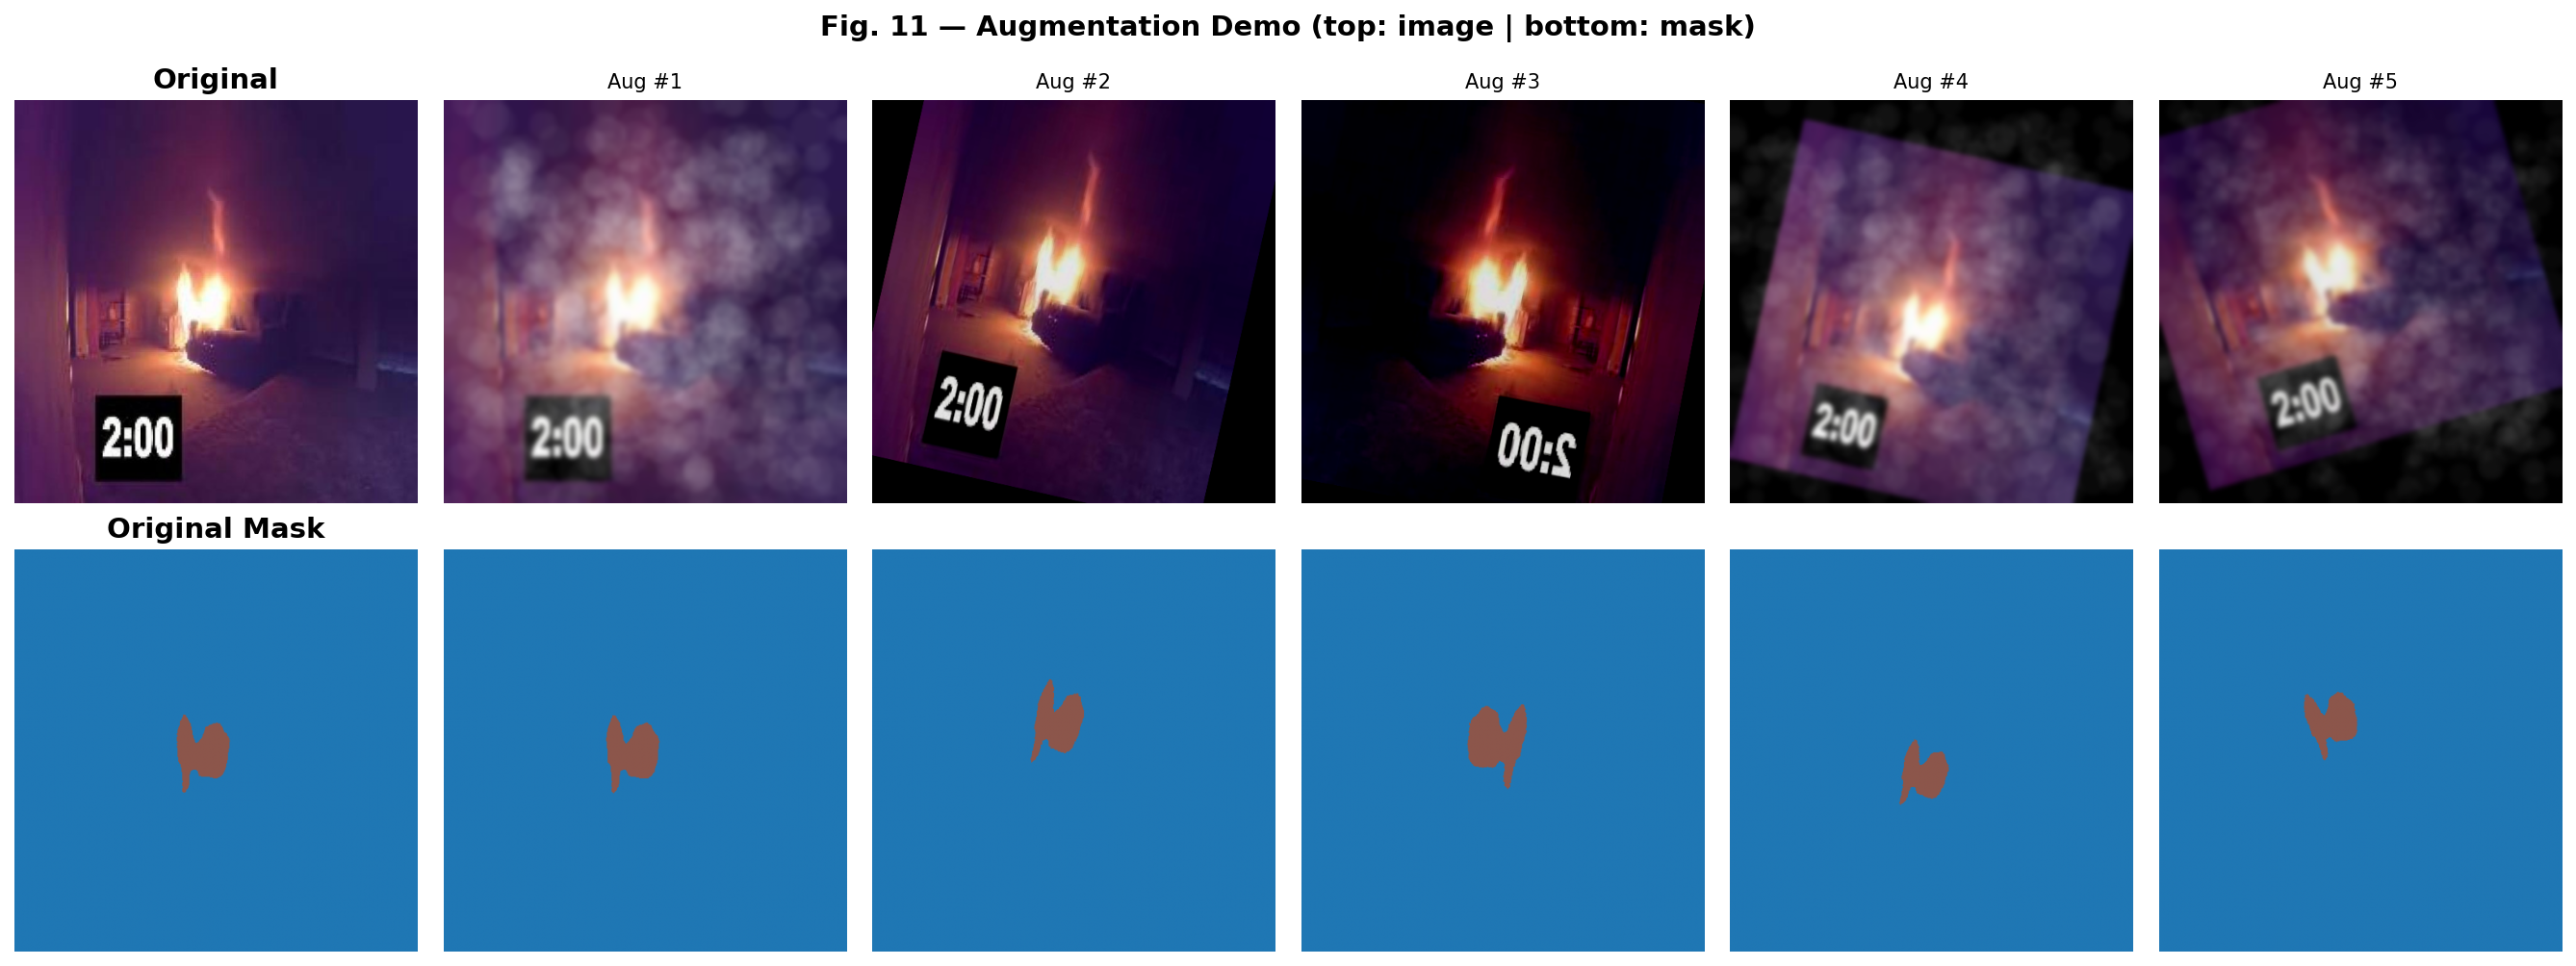

✅ Saved: fig11_augmentation_demo.png


In [28]:
# ===== PHASE 3.4: Demo augmentation — xem kết quả trực quan =====

# Lấy 1 ảnh có fire/smoke để demo
demo_base = None
for _, row in df.iterrows():
    if row.get('n_fg_classes', 0) > 0:
        demo_base = row['basename']
        break

if demo_base is None:
    demo_base = df.iloc[0]['basename']

# Đọc ảnh demo
demo_img  = np.array(Image.open(images[demo_base]).convert('RGB'))
demo_mask = mask_to_classmap(masks[demo_base], MASK_MODE, CLASS_MAP)

# Augmentation transform (chỉ geometric + color, không normalize)
aug_demo = A.Compose([
    A.LongestMaxSize(max_size=512),
    A.PadIfNeeded(min_height=512, min_width=512,
                  border_mode=cv2.BORDER_CONSTANT, value=0, mask_value=0),
    A.HorizontalFlip(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.15, rotate_limit=20,
                       border_mode=cv2.BORDER_CONSTANT, p=0.8),
    A.RandomBrightnessContrast(brightness_limit=0.3, contrast_limit=0.3, p=0.8),
    A.RandomFog(fog_coef_lower=0.05, fog_coef_upper=0.2, p=0.5),
    A.RandomCrop(height=512, width=512),
])

# Tạo grid: 1 gốc + 5 augmented
N_AUG = 5
fig, axes = plt.subplots(2, N_AUG+1, figsize=(18, 7))
fig.suptitle('Fig. 11 — Augmentation Demo (top: image | bottom: mask)',
             fontsize=14, fontweight='bold')

# Hiện ảnh gốc
axes[0][0].imshow(cv2.resize(demo_img, (512,512)))
axes[0][0].set_title('Original', fontweight='bold')
axes[0][0].axis('off')
axes[1][0].imshow(cv2.resize(demo_mask, (512,512)), cmap='tab20', vmin=0, vmax=N_CLASSES-1)
axes[1][0].set_title('Original Mask', fontweight='bold')
axes[1][0].axis('off')

# Hiện 5 augmentations
for i in range(1, N_AUG+1):
    augmented = aug_demo(image=demo_img, mask=demo_mask)
    axes[0][i].imshow(augmented['image'])
    axes[0][i].set_title(f'Aug #{i}', fontsize=10)
    axes[0][i].axis('off')
    axes[1][i].imshow(augmented['mask'], cmap='tab20', vmin=0, vmax=N_CLASSES-1)
    axes[1][i].axis('off')

plt.tight_layout()
fig.savefig(EDA_OUT / 'fig11_augmentation_demo.png', bbox_inches='tight', dpi=200)
plt.show()
print('✅ Saved: fig11_augmentation_demo.png')

In [29]:
# ===== PHASE 3.5: Oversampling Strategy =====
# Tăng trọng số sampling cho ảnh có fire/smoke nhỏ

def compute_sample_weights(df, fg_classes, small_threshold=5.0, weight_small=5.0):
    """
    Tính sample weight cho từng ảnh:
    - Ảnh background only: weight = 1.0
    - Ảnh có foreground lớn: weight = 2.0
    - Ảnh có foreground nhỏ (<threshold%): weight = weight_small
    """
    weights = []
    for _, row in df.iterrows():
        w = 1.0
        for cname in fg_classes:
            pct_col = f'pct_{cname}'
            has_col = f'has_{cname}'
            if has_col not in row.index: continue
            if row[has_col]:
                pct = row.get(pct_col, 0)
                if pct < small_threshold:
                    w = max(w, weight_small)  # nhỏ → oversample nhiều
                else:
                    w = max(w, 2.0)           # lớn → oversample vừa
        weights.append(w)
    return weights


fg_cls = [n for n in CLASS_NAMES if n != 'background']
sample_weights = compute_sample_weights(df, fg_cls)
df['sample_weight'] = sample_weights

# Thống kê
weight_counts = Counter(sample_weights)
print('📊 Phân bố Sample Weights:')
for w in sorted(weight_counts.keys()):
    n = weight_counts[w]
    print(f'   weight={w:.1f} → {n} ảnh ({100*n/len(df):.1f}%)')

print('\nGợi ý: Dùng torch.utils.data.WeightedRandomSampler với weights này')
print('để PyTorch DataLoader tự động oversample ảnh có fire/smoke nhỏ.')

📊 Phân bố Sample Weights:
   weight=1.0 → 60 ảnh (6.4%)
   weight=2.0 → 207 ảnh (22.1%)
   weight=5.0 → 668 ảnh (71.4%)

Gợi ý: Dùng torch.utils.data.WeightedRandomSampler với weights này
để PyTorch DataLoader tự động oversample ảnh có fire/smoke nhỏ.


---
# 🧹 PHASE 4 — Tiền xử lý & PyTorch Dataset

## 4.1 — Stratified Train/Val/Test Split

In [31]:
# ===== PHASE 4.1: Stratified Split =====

from sklearn.model_selection import train_test_split

# Tỉ lệ split
TRAIN_RATIO = 0.70
VAL_RATIO   = 0.15
TEST_RATIO  = 0.15
RANDOM_SEED = 42

# Stratify theo category (background_only / fire / smoke / ...)
all_bases  = df['basename'].tolist()
categories = df['category'].tolist()

# Vì một số category có thể ít mẫu, thử stratify trước
try:
    train_bases, temp_bases, train_cats, temp_cats = train_test_split(
        all_bases, categories,
        test_size=(1 - TRAIN_RATIO),
        stratify=categories,
        random_state=RANDOM_SEED
    )
    val_ratio_adjusted = VAL_RATIO / (VAL_RATIO + TEST_RATIO)
    val_bases, test_bases = train_test_split(
        temp_bases,
        test_size=(1 - val_ratio_adjusted),
        stratify=temp_cats,
        random_state=RANDOM_SEED
    )
    print('✅ Stratified split thành công!')

except ValueError as e:
    print(f'⚠️  Stratified split thất bại ({e}), dùng random split.')
    train_bases, temp_bases = train_test_split(
        all_bases, test_size=(1 - TRAIN_RATIO), random_state=RANDOM_SEED)
    val_bases, test_bases = train_test_split(
        temp_bases, test_size=0.5, random_state=RANDOM_SEED)

print(f'\n📊 Split result:')
print(f'   Train : {len(train_bases)} ảnh ({100*len(train_bases)/len(df):.1f}%)')
print(f'   Val   : {len(val_bases)} ảnh ({100*len(val_bases)/len(df):.1f}%)')
print(f'   Test  : {len(test_bases)} ảnh ({100*len(test_bases)/len(df):.1f}%)')

# Kiểm tra phân bố category trong từng split
print('\n📋 Phân bố Category trong splits:')
for split_name, split_bases in [('Train', train_bases), ('Val', val_bases), ('Test', test_bases)]:
    split_df = df[df['basename'].isin(split_bases)]
    print(f'  [{split_name}]')
    for cat, cnt in split_df['category'].value_counts().items():
        print(f'    {cat}: {cnt}')

✅ Stratified split thành công!

📊 Split result:
   Train : 654 ảnh (69.9%)
   Val   : 140 ảnh (15.0%)
   Test  : 141 ảnh (15.1%)

📋 Phân bố Category trong splits:
  [Train]
    Fire only: 297
    Smoke only: 213
    Fire + Smoke: 102
    Background only: 42
  [Val]
    Fire only: 63
    Smoke only: 46
    Fire + Smoke: 22
    Background only: 9
  [Test]
    Fire only: 64
    Smoke only: 46
    Fire + Smoke: 22
    Background only: 9


In [32]:
# Lưu split ra CSV
for split_name, split_bases in [('train', train_bases), ('val', val_bases), ('test', test_bases)]:
    split_df = df[df['basename'].isin(split_bases)][['basename', 'img_path', 'mask_path', 'category', 'sample_weight']]
    out_path = EDA_OUT / f'split_{split_name}.csv'
    split_df.to_csv(out_path, index=False)
    print(f'✅ Saved: {out_path.name} ({len(split_df)} rows)')

✅ Saved: split_train.csv (654 rows)
✅ Saved: split_val.csv (140 rows)
✅ Saved: split_test.csv (141 rows)


In [33]:
# ===== PHASE 4.2: Quality Check — phát hiện ảnh lỗi =====

print('🔍 Quality Check...')
issues = []

for base in tqdm(paired_list, desc='Checking quality'):
    img_path  = images[base]
    mask_path = masks[base]

    # Kiểm tra ảnh
    try:
        img = Image.open(img_path)
        img.verify()  # kiểm tra corrupt
    except Exception as e:
        issues.append({'basename': base, 'issue': f'Corrupt image: {e}'})
        continue

    # Kiểm tra size
    row = df[df['basename'] == base]
    if len(row) > 0:
        if not row.iloc[0]['size_match']:
            issues.append({'basename': base, 'issue': 'Image/mask size mismatch'})

        # Ảnh quá nhỏ (< 64x64)
        if row.iloc[0]['width'] < 64 or row.iloc[0]['height'] < 64:
            issues.append({'basename': base, 'issue': f'Image too small: {row.iloc[0]["width"]}x{row.iloc[0]["height"]}'})

if issues:
    print(f'⚠️  Tìm thấy {len(issues)} vấn đề:')
    for iss in issues[:20]:
        print(f'   [{iss["basename"][:40]}...] → {iss["issue"]}')
    df_issues = pd.DataFrame(issues)
    df_issues.to_csv(EDA_OUT / 'quality_issues.csv', index=False)
    print(f'\n📁 Đã lưu: quality_issues.csv')
else:
    print('✅ Không phát hiện vấn đề chất lượng!')

🔍 Quality Check...


Checking quality:   0%|          | 0/935 [00:00<?, ?it/s]

✅ Không phát hiện vấn đề chất lượng!


In [34]:
# ===== PHASE 4.3: PyTorch Dataset class =====

import torch
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision.transforms.functional as TF


class FireSmokeDataset(Dataset):
    """
    PyTorch Dataset cho Fire & Smoke Semantic Segmentation.

    Parameters
    ----------
    df          : pandas DataFrame với cột img_path, mask_path
    mask_mode   : 'RGB' hoặc 'GRAY'
    class_map   : dict mapping pixel value/color → class id
    n_classes   : số lớp
    transform   : albumentations Compose pipeline
    """

    def __init__(self, df, mask_mode, class_map, n_classes, transform=None):
        self.df         = df.reset_index(drop=True)
        self.mask_mode  = mask_mode
        self.class_map  = class_map
        self.n_classes  = n_classes
        self.transform  = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        # --- Load image ---
        image = np.array(Image.open(row['img_path']).convert('RGB'), dtype=np.uint8)

        # --- Load & decode mask ---
        mask = mask_to_classmap(row['mask_path'], self.mask_mode, self.class_map)
        mask = mask.astype(np.int64)

        # --- Apply augmentations ---
        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented['image']   # Tensor [C, H, W]
            mask  = augmented['mask']    # Tensor [H, W]
        else:
            image = torch.from_numpy(image.transpose(2, 0, 1)).float() / 255.0
            mask  = torch.from_numpy(mask).long()

        return image, mask

    def get_sample_weights(self):
        """Trả về danh sách sample weights cho WeightedRandomSampler."""
        return self.df['sample_weight'].fillna(1.0).tolist()


# --- Tạo DataLoaders ---
def create_dataloaders(train_df, val_df, test_df,
                       mask_mode, class_map, n_classes,
                       train_transform, val_transform,
                       batch_size=8, num_workers=4,
                       use_weighted_sampler=True):

    train_ds = FireSmokeDataset(train_df, mask_mode, class_map, n_classes, train_transform)
    val_ds   = FireSmokeDataset(val_df,   mask_mode, class_map, n_classes, val_transform)
    test_ds  = FireSmokeDataset(test_df,  mask_mode, class_map, n_classes, val_transform)

    if use_weighted_sampler:
        sw = train_ds.get_sample_weights()
        sampler = WeightedRandomSampler(
            weights=sw, num_samples=len(sw), replacement=True
        )
        train_loader = DataLoader(train_ds, batch_size=batch_size,
                                  sampler=sampler, num_workers=num_workers,
                                  pin_memory=True, prefetch_factor=2)
    else:
        train_loader = DataLoader(train_ds, batch_size=batch_size,
                                  shuffle=True, num_workers=num_workers,
                                  pin_memory=True, prefetch_factor=2)

    val_loader  = DataLoader(val_ds,  batch_size=batch_size, shuffle=False,
                             num_workers=num_workers, pin_memory=True)
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False,
                             num_workers=num_workers, pin_memory=True)

    return train_loader, val_loader, test_loader, train_ds, val_ds, test_ds


print('✅ FireSmokeDataset class & create_dataloaders định nghĩa xong!')

✅ FireSmokeDataset class & create_dataloaders định nghĩa xong!


In [ ]:
# ===== PHASE 4.4: Khởi tạo & Kiểm tra DataLoaders =====

train_df = df[df['basename'].isin(train_bases)].copy()
val_df   = df[df['basename'].isin(val_bases)].copy()
test_df  = df[df['basename'].isin(test_bases)].copy()

BATCH_SIZE   = 8
NUM_WORKERS  = 2  # Đặt 0 trên Windows để tránh lỗi multiprocessing

train_loader, val_loader, test_loader, train_ds, val_ds, test_ds = create_dataloaders(
    train_df, val_df, test_df,
    MASK_MODE, CLASS_MAP, N_CLASSES,
    train_transform, val_transform,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    use_weighted_sampler=True
)

print(f'✅ DataLoaders tạo xong!')
print(f'   Train batches : {len(train_loader)}')
print(f'   Val batches   : {len(val_loader)}')
print(f'   Test batches  : {len(test_loader)}')

# Test lấy 1 batch
sample_imgs, sample_masks = next(iter(train_loader))
print(f'\n  Batch sample:')
print(f'   Images shape : {sample_imgs.shape}  dtype={sample_imgs.dtype}')
print(f'   Masks  shape : {sample_masks.shape}  dtype={sample_masks.dtype}')
print(f'   Unique mask values in batch: {sample_masks.unique().tolist()}')

✅ DataLoaders tạo xong!
   Train batches : 82
   Val batches   : 18
   Test batches  : 18


In [ ]:
# ===== PHASE 4.5: Visualize batch từ DataLoader =====

IMAGENET_MEAN = np.array([0.485, 0.456, 0.406])
IMAGENET_STD  = np.array([0.229, 0.224, 0.225])

def denormalize(tensor):
    """Denormalize ImageNet tensor → uint8 numpy."""
    img = tensor.cpu().numpy().transpose(1, 2, 0)
    img = img * IMAGENET_STD + IMAGENET_MEAN
    return np.clip(img * 255, 0, 255).astype(np.uint8)


n_show = min(BATCH_SIZE, 4)
fig, axes = plt.subplots(2, n_show, figsize=(4*n_show, 8))
fig.suptitle('Fig. 12 — Batch từ DataLoader (post-augmentation)\n'
             'Top: Image | Bottom: Mask',
             fontsize=13, fontweight='bold')

cmap_mask = plt.cm.get_cmap('tab10', N_CLASSES)

for i in range(n_show):
    img_show  = denormalize(sample_imgs[i])
    mask_show = sample_masks[i].cpu().numpy()

    axes[0][i].imshow(img_show)
    axes[0][i].set_title(f'Image #{i+1}', fontsize=10)
    axes[0][i].axis('off')

    im = axes[1][i].imshow(mask_show, cmap=cmap_mask, vmin=0, vmax=N_CLASSES-1)
    axes[1][i].set_title(f'Mask #{i+1}', fontsize=10)
    axes[1][i].axis('off')

# Colorbar legend
cbar = fig.colorbar(im, ax=axes[1], fraction=0.02, pad=0.04)
cbar.set_ticks(range(N_CLASSES))
cbar.set_ticklabels(CLASS_NAMES)

plt.tight_layout()
fig.savefig(EDA_OUT / 'fig12_dataloader_batch.png', bbox_inches='tight', dpi=200)
plt.show()
print('✅ Saved: fig12_dataloader_batch.png')

---
# 📝 TỔNG KẾT PIPELINE

## Checklist hoàn thành

In [ ]:
# ===== TỔNG KẾT TOÀN BỘ PIPELINE =====

print('='*65)
print('🎉 PIPELINE HOÀN THÀNH — CHECKLIST')
print('='*65)

print()
print('✅ PHASE 1 — Tách thư mục:')
print(f'   images/ : {len(list(IMAGES_DIR.glob("*.jpg")))} ảnh')
print(f'   masks/  : {len(list(MASKS_DIR.glob("*_mask.png")))} masks')

print()
print('✅ PHASE 2 — EDA Figures (lưu tại docs/eda_figures/):')
for fig_file in sorted(EDA_OUT.glob('fig*.png')):
    size_kb = fig_file.stat().st_size / 1024
    print(f'   📊 {fig_file.name} ({size_kb:.0f} KB)')

print()
print('✅ PHASE 3 — Xử lý mất cân bằng:')
print('   - Focal Loss (γ=2.0)')
print('   - Dice Loss')
print('   - Tversky Loss (α=0.7)')
print('   - Combined Focal+Dice Loss')
print('   - Augmentation pipeline (Albumentations, 15+ transforms)')
print('   - Oversampling weights đã tính')

print()
print('✅ PHASE 4 — Preprocessing:')
print(f'   - Train/Val/Test split: {len(train_bases)}/{len(val_bases)}/{len(test_bases)}')
print(f'   - FireSmokeDataset class (PyTorch)')
print(f'   - WeightedRandomSampler cho oversampling')
print(f'   - DataLoaders sẵn sàng (batch_size={BATCH_SIZE})')
print()

print('📁 Các file xuất ra:')
for f in sorted(EDA_OUT.iterdir()):
    print(f'   {f.name} ({f.stat().st_size/1024:.1f} KB)')

print()
print('⚙️  Cấu hình training gợi ý:')
print(f'   Model        : SegFormer-B2')
print(f'   Image size   : {IMG_SIZE}×{IMG_SIZE}')
print(f'   Batch size   : {BATCH_SIZE}')
print(f'   Loss         : CombinedLoss(Focal + Dice, weights={list(np.round(weights_median,3))})')
print(f'   Optimizer    : AdamW (lr=6e-5, weight_decay=0.01)')
print(f'   Scheduler    : CosineAnnealing + Linear Warmup')
print(f'   Epochs       : 50-100')
print('='*65)